# Biopharmaceutical process development: a workbench you drive

Upstream fed-batch culture through downstream purification to release, with the
data-driven layer the field actually uses on top: MVDA and ML on batch records,
a Raman soft sensor, a hybrid mechanistic/ML model, global sensitivity and
uncertainty.

**It asks before each step.** Every section opens with a question. Answer it, or
press Enter to take the default from `configs/systems/<name>.toml`. Run it
headless and the same defaults are used without asking, so the committed
outputs are reproducible. Your answers are recorded, shown in section 14, and
can be saved and replayed with `BIOPROC_ANSWERS`.

**How to read the output.**

| Status | Meaning |
|---|---|
| `PASS` | A check against a known answer succeeded |
| `FAIL` | It did not. The last cell raises an error listing every failure |
| `WARN` | Not wrong, but you need to know |
| `INFO` | A result that is reported, not asserted |
| `OUT OF SPEC` | The *process* missed a criterion. A finding, not a code failure |

**Synthetic data warning.** With `data_source = "simulate"` every number below is
generated from the kinetic parameters in the config. That is a positive control:
it shows the analysis recovers an answer that is known in advance. It is *not*
evidence about any real cell line, resin or product. Section 2 will offer to
load your own export or an open dataset instead.

## Sections

| | Section | Question it answers |
|---|---|---|
| 0 | Setup and system | Which process, which seed, where does data go? |
| 1 | Verification | Does the code solve the equations correctly? |
| 2 | Data source | Simulate, load your export, or fetch an open dataset? |
| 3 | Upstream culture | How does one batch run, and what does it harvest? |
| 4 | Feed strategy | Does feedback feeding beat a fixed bolus, and by how much? |
| 5 | Campaign | What does batch-to-batch variation look like? |
| 6 | Sensitivity | Which parameters actually move the titer? |
| 7 | Uncertainty | What interval, not what single number? |
| 8 | Batch KPI models | Can PLS/RF/GP predict the KPI better than the mean? |
| 9 | Soft sensor | Can a Raman-like spectrum replace an offline assay? |
| 10 | Hybrid model | Does adding a data-driven rate to the mechanism help? |
| 11 | Capture chromatography | What is the DBC, and how many cycles? |
| 12 | Purification train | What yield and what impurity clearance, end to end? |
| 13 | Release and control | Does the batch meet spec; is the process stable and capable? |
| 14 | Record | What was run, with what answers, on what software? |

Scope. Glycosylation, viral clearance validation, media design, GMP
documentation and regulatory submission are out of scope. The models here are
screening tools: unstructured kinetics upstream, a lumped kinetic model for
capture, correlations for polishing.

## 0. Setup and system

> **Kernel.** Select **`Python (bioproc)`** before running anything — in VS Code
> via the kernel name at the top right, in Jupyter Lab via *Kernel → Change
> Kernel*. Any other kernel fails on the imports below, because the package and
> its pinned NumPy/SciPy/scikit-learn live in that environment. The first cell
> checks this and says what to do.
>
> If `Python (bioproc)` is not offered, the environment has not been created:
> see *Install* in the README.

Imports, the system config, the random seed, and the directory for generated
data. Everything specific to a process lives in the config; the code below is
the same for every system.

In [1]:
# Preflight: is this the right kernel? Run this first.
#
# The usual first failure is a notebook opened with whichever kernel the editor
# used last, which reports only "No module named 'bioproc'". That says nothing
# about what to do, so this cell says it instead.
import sys
from pathlib import Path

PREFIX = Path(sys.prefix)
ENVIRONMENT = PREFIX.name if PREFIX.parent.name == "envs" else f"{PREFIX} (not a named conda env)"


def _short(path) -> str:
    # This notebook is committed with its outputs, so anything printed here is
    # published. A reader needs to know which environment ran it, not where the
    # home directory of the machine that ran it happens to be. bioproc.ui has
    # the real version of this, but it cannot be imported yet - that is the
    # thing being checked.
    text = str(path)
    home = str(Path.home())
    return ("~" + text[len(home):]).replace("\\", "/") if text.startswith(home) else text


print(f"kernel environment : {ENVIRONMENT}")
print(f"interpreter        : {_short(sys.executable)}")

try:
    import bioproc
except ModuleNotFoundError as error:
    raise ModuleNotFoundError(
        f"\n\nThis notebook is running in '{ENVIRONMENT}', which does not have bioproc.\n"
        f"  interpreter: {sys.executable}\n\n"
        "Pick the right kernel instead of installing into this one:\n"
        "  VS Code     - click the kernel name at the top right, then\n"
        "                Select Another Kernel -> Jupyter Kernel -> 'Python (bioproc)'\n"
        "  Jupyter Lab - Kernel -> Change Kernel -> 'Python (bioproc)'\n\n"
        "If 'Python (bioproc)' is not offered, the environment is not set up yet:\n"
        "  conda env create -f environment.yml\n"
        "  conda activate bioproc\n"
        "  pip install -e . --no-deps\n"
        "  python tools/install_kernel.py\n\n"
        "Installing bioproc into the current environment would run the notebook on that\n"
        "environment's numpy, scipy and scikit-learn, which are not the pinned ones, so\n"
        "it is not done for you."
    ) from error

# Now that the import worked, use the real shortener: it resolves against the
# repository root, so this reads "src/bioproc" and confirms the editable install
# is being used rather than a stray copy in site-packages.
from bioproc.ui import short_path

print(f"bioproc            : {bioproc.__version__} from {short_path(Path(bioproc.__file__).parent)}")

kernel environment : bioproc
interpreter        : ~/anaconda3/envs/bioproc/python.exe
bioproc            : 0.1.0 from src/bioproc


In [2]:
import json
import os
import platform
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from bioproc import (
    config as cfg,
    data,
    downstream,
    evaluation,
    models,
    plotting,
    quality,
    simulators,
    ui,
    upstream,
    uq,
    verification,
)

SYSTEM = os.environ.get("BIOPROC_SYSTEM", "demo_intensified")
config = cfg.load_system(SYSTEM)
SEED = int(config["system"]["seed"])
DATA = ui.data_directory() / SYSTEM        # outside OneDrive and the repo
FIGURES = DATA / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
NOTEBOOK_START = time.perf_counter()

plotting.apply_style()
pd.set_option("display.width", 130, "display.max_columns", 40, "display.float_format", lambda v: f"{v:,.4g}")

# Warnings are kept - a convergence warning from a fit is often the most useful
# line in a cell - but the default format prefixes each one with the absolute
# path of the library file that raised it. That path says nothing about the
# result and writes this machine's layout into a notebook that is committed with
# its outputs, so only the category and the message are shown.
import warnings

warnings.formatwarning = lambda message, category, *_args, **_kwargs: f"{category.__name__}: {message}\n"

# Every question in this notebook goes through this session. It prompts at a
# keyboard and falls back to the config's [answers] table when there is none.
ask = ui.Session(cfg.answers(config))
CHECKS = []          # verification.Check, asserted at the end
FINDINGS = []        # process findings: real, but not code failures

display(Markdown(f'''
**System** `{SYSTEM}` - {config["system"]["name"]}
**Product** {config["system"]["product"]} | **Cell line** {config["system"]["cell_line"]}
**Context of use** {config["system"]["context_of_use"]}
**Seed** {SEED} | **Data directory** `{ui.short_path(DATA)}`
'''))


**System** `demo_intensified` - Demo intensified CHO process, 21-day, high-density
**Product** Fc-fusion protein | **Cell line** CHO (illustrative parameters, not a fitted line)
**Context of use** Screen whether a high-density inoculum with a low glucose setpoint raises harvested mass per litre over the 14-day baseline, and whether the smaller capture column still clears aggregate to a 1.5% specification. Screening only.
**Seed** 20261116 | **Data directory** `~/bioproc-data/demo_intensified`


In [3]:
# Which optional simulators are installed. None is required: the notebook has a
# built-in model for every step and says which engine produced each number.
engines = simulators.detect()
display(engines[["key", "available", "version", "purpose"]])
missing = engines.loc[~engines["available"], "key"].tolist()
print(f"\nINFO built-in models used for: {', '.join(missing) if missing else 'nothing - all optional engines available'}")
if missing:
    print("      install commands are in the 'install' column; see README 'Optional simulators'")

,key,available,version,purpose
0,cadet,False,,"Rigorous chromatography models (GRM, SMB) - cr..."
1,biosteam,False,,"Techno-economic analysis: cost of goods, utili..."
2,idaes,False,,Equation-oriented flowsheet modelling and opti...
3,dwsim,False,,Steady-state and dynamic flowsheeting (.NET de...



INFO built-in models used for: cadet, biosteam, idaes, dwsim
      install commands are in the 'install' column; see README 'Optional simulators'


## 1. Verification: does the code solve the equations correctly?

Before any result. Verification asks whether the implementation is right;
validation (are these the right equations?) needs independent experimental data
and is section 13's job. Checks here use closed-form answers where one exists,
conservation of mass, and a time-step convergence study with the observed order.

The first question: run the convergence study, which is the slow one?

In [4]:
run_convergence = ask.ask(
    "run_convergence_study",
    "Run the time-step convergence study? (a few seconds; it reports the observed order)",
    bool,
)

# 1a. Analytic: with nutrients in excess and death off, the model must reproduce
# x0*exp(mu*t) exactly. This tests the integrator against a known answer.
def unlimited_growth(mu_per_h, x0, hours):
    parameters = upstream.CHOParameters(
        mu_max_per_h=mu_per_h, kd_min_per_h=0.0, kd_amm_max_per_h=0.0, kd_starve_per_h=0.0,
        qp_beta_mg_per_1e9cells_h=0.0, m_glc_mmol_per_1e9cells_h=0.0, m_gln_mmol_per_1e9cells_h=0.0,
        k_gln_degradation_per_h=0.0, y_lac_glc_mol_per_mol=0.0, y_amm_gln_mol_per_mol=0.0,
        ks_glc_mM=1e-9, ks_gln_mM=1e-9, ki_lac_mM=1e12, ki_amm_mM=1e12,
    )
    state = {"xv": x0, "xd": 0.0, "glc": 1e6, "gln": 1e6, "lac": 0.0, "amm": 0.0, "titer": 0.0, "volume": 1.0}
    history = upstream.simulate(state, parameters, duration_h=hours, sample_interval_h=hours)
    return float(history["xv"].iloc[-1])

CHECKS.append(verification.verify_growth_against_analytic(unlimited_growth, 0.03, 0.5, 48.0))

# 1b. Are the kinetic parameters even plausible? A set whose specific rates are
# an order of magnitude out starves the culture in three days however carefully
# everything downstream is done - which is exactly what the first version of
# these defaults did. Reported here before any result is read.
rates = upstream.rate_check(cfg.cho_parameters(config))
display(rates)
outside = rates[~rates["in_range"]]
if outside.empty:
    print("INFO every specific rate is inside the range reported for CHO fed-batch culture")
else:
    for _, row in outside.iterrows():
        FINDINGS.append(
            f"{row['quantity']} = {row['value']:.3g}, outside the reported "
            f"{row['reported_low']:g}-{row['reported_high']:g}"
        )
        print(f"WARN {FINDINGS[-1]}")
    print("     An unusual clone is allowed, but it should be a deliberate choice, not a typo.")

# 1c. The Langmuir isotherm against its closed form.
resin = cfg.capture_resin(config)
CHECKS.append(verification.verify_langmuir_equilibrium(resin, 1.5))

# 1d. Ideal diafiltration: retained fraction exp(-N).
probe = downstream.ufdf_step(100.0, 20.0, target_concentration_g_per_L=50.0, diavolumes=7.0)
CHECKS.append(verification.verify_diafiltration(probe["buffer_exchange_fraction"], 7.0))

display(verification.summarise(CHECKS))

  run_convergence_study = True   (default (no keyboard))


,quantity,value,reported_low,reported_high,in_range
0,doubling_time_h,18.86,18,35,True
1,q_glc_pmol_per_cell_day,0.3629,0.15,0.6,True
2,q_gln_pmol_per_cell_day,0.08288,0.03,0.2,True
3,q_lac_pmol_per_cell_day,0.4355,0.1,0.8,True
4,qp_pg_per_cell_day,28.8,5,40,True


INFO every specific rate is inside the range reported for CHO fed-batch culture


,check,status,observed,expected,relative_error,tolerance,note
0,Batch growth matches x0*exp(mu*t) with nutrien...,PASS,2.11,2.11,4.489e-09,0.002,Analytic solution of the model's own limiting ...
1,Langmuir isotherm closed form,PASS,50.77,50.77,0,1e-10,
2,Diafiltration buffer exchange = 1 - exp(-N),PASS,0.9991,0.9991,0,1e-09,"Fully permeable solute, perfectly mixed retentate"


In [5]:
if run_convergence:
    # Refine the integrator's maximum step and watch the titer converge. The
    # finest step is the reference, so this measures self-convergence.
    reference_state = cfg.initial_state(config)
    reference_parameters = cfg.cho_parameters(config)
    policy = cfg.feed_policy(config, "glucose_setpoint")

    def titer_at_step(max_step_h):
        history = upstream.simulate(
            reference_state, reference_parameters, duration_h=7 * 24, sample_interval_h=24.0,
            feed_policy=policy, shift_time_h=float(config["upstream"]["shift_time_h"]),
            max_step_h=float(max_step_h),
        )
        return float(history["titer"].iloc[-1])

    table, order = verification.convergence_study(titer_at_step, [4.0, 2.0, 1.0, 0.5, 0.25])
    display(table)

    # LSODA chooses its own step to meet rtol/atol, so max_step is a cap rather
    # than the step actually taken. Once the cap stops binding the differences
    # are solver noise, and fitting a slope through noise produces a number that
    # looks like an order of convergence but is not one. Say which case this is.
    coarsest_error = float(table["relative_error"].iloc[0])
    if coarsest_error < 1e-6:
        print(f"INFO the titer is already converged at the coarsest cap (max_step = "
              f"{table['step'].iloc[0]:g} h, relative difference {coarsest_error:.1e}).")
        print("     An order of convergence cannot be estimated from differences this small:")
        print("     they are solver noise, not discretisation error. The adaptive step, not the")
        print("     cap, is controlling the error here, and rtol = 1e-7 is what sets it.")
    else:
        print(f"INFO observed order in the step cap: {order:.2f} "
              f"(relative difference {coarsest_error:.1e} at the coarsest cap)")

    CHECKS.append(verification.close(
        "Titer is converged at max_step = 1 h",
        table.loc[table['step'] == 1.0, 'relative_error'].iloc[0], 0.0, 1e-3,
        "relative to the 0.25 h solution",
    ))
    display(verification.summarise(CHECKS))
else:
    print("INFO convergence study skipped; the production runs below use max_step = 1 h")

,step,value,abs_error,relative_error
0,4,"3,547",0.0003434,9.681e-08
1,2,"3,547",0.0002715,7.653e-08
2,1,"3,547",0.0001635,4.608e-08
3,0.5,"3,547",0.0002937,8.281e-08
4,0.25,"3,547",0,0


INFO the titer is already converged at the coarsest cap (max_step = 4 h, relative difference 9.7e-08).
     An order of convergence cannot be estimated from differences this small:
     they are solver noise, not discretisation error. The adaptive step, not the
     cap, is controlling the error here, and rtol = 1e-7 is what sets it.


,check,status,observed,expected,relative_error,tolerance,note
0,Batch growth matches x0*exp(mu*t) with nutrien...,PASS,2.11,2.11,4.489e-09,0.002,Analytic solution of the model's own limiting ...
1,Langmuir isotherm closed form,PASS,50.77,50.77,0,1e-10,
2,Diafiltration buffer exchange = 1 - exp(-N),PASS,0.9991,0.9991,0,1e-09,"Fully permeable solute, perfectly mixed retentate"
3,Titer is converged at max_step = 1 h,PASS,4.608e-08,0,4.608e-08,0.001,relative to the 0.25 h solution


## 2. Where does the data come from?

Three options, and the notebook states which one it used on every figure.

1. **`simulate`** - generate batches from the mechanistic model with a stated
   ground truth. A positive control for the whole analysis.
2. **`file`** - your own CSV or Excel export. You will be asked to map your
   column names onto the canonical ones; nothing is guessed, and units are
   never inferred from magnitude (ground rules section 2).
3. **`open_dataset`** - the anonymised CHO upstream set published with
   Gangadharan et al. (2021), doi:10.1016/j.compchemeng.2021.107226, fetched
   with a checksum. It is normalised to 0-1 by its authors, so it carries **no
   units**: the notebook refuses to attach any, and reports normalised errors
   only.

In [6]:
source = ask.ask(
    "data_source", "Where should the batch data come from?", str,
    choices=["simulate", "file", "open_dataset"],
    help="simulate = synthetic positive control; file = your export; open_dataset = published CHO data",
)

samples = batches = None
truth = {}
UNITS_KNOWN = True
PROVENANCE = {}

if source == "simulate":
    n_batches = ask.ask("n_batches", "How many batches in the campaign?", int, minimum=2, maximum=60)
    duration_d = ask.ask("duration_d", "Culture duration", float, unit="d", minimum=1, maximum=40)
    shift_day = ask.ask("shift_day", "Temperature-shift day (use 99 for no shift)", float, unit="d", minimum=0)
    lot_cv = ask.ask("lot_variation_cv", "Lot-to-lot variation in growth and productivity (CV)",
                     float, minimum=0.0, maximum=0.5)
    samples, batches, truth = data.simulate_campaign(
        n_batches, seed=SEED, duration_h=duration_d * 24,
        sample_interval_h=float(config["upstream"]["sample_interval_h"]),
        shift_time_h=shift_day * 24, lot_variation_cv=lot_cv,
        parameters=cfg.cho_parameters(config),
    )
    PROVENANCE = {"source": "simulated", "generator": truth["generator"], "seed": SEED}
    print(f"\nWARN SYNTHETIC DATA. {truth['warning']}")

elif source == "file":
    path = ask.ask_path("batch_file", "Path to your batch export (.csv or .xlsx), or 'none' to fall back to simulation",
                        suffixes=[".csv", ".xlsx", ".xls"])
    if path is None:
        raise ValueError("no file given; re-run and choose 'simulate', or supply a path")
    preview = pd.read_csv(path, nrows=5) if path.suffix.lower() == ".csv" else pd.read_excel(path, nrows=5)
    print("Columns found:", list(preview.columns))
    mapping = {}
    for canonical in ["batch_id", "time_h", "vcd_1e6_per_mL", "glucose_mM", "lactate_mM", "titer_mg_per_L"]:
        answer = ask.ask(f"map_{canonical}", f"Which of your columns is {canonical}? ('-' to skip)", str,
                         default="-", help=f"available: {list(preview.columns)[:12]}")
        if answer != "-":
            mapping[answer] = canonical
    declared = ask.ask("units_declared", "Have you confirmed the units of those columns against the file's own documentation?", bool)
    samples = data.read_batch_table(path, mapping, units_declared=declared)
    UNITS_KNOWN = declared
    PROVENANCE = {"source": str(path), "sha256": samples.attrs["source_sha256"],
                  "read_on": samples.attrs["read_on"], "units_declared": declared}
    if not declared:
        print("WARN units are not confirmed. Absolute values below are NOT interpretable; use them for trends only.")

else:
    try:
        path, record = data.fetch_open_dataset("gangadharan2021_cho")
        PROVENANCE = record
        UNITS_KNOWN = False
        print(f"INFO {record['citation']}")
        print(f"WARN {record['note']}")
        print("WARN the dataset is 0-1 normalised, so it carries no units; errors below are normalised only")
        samples = pd.read_excel(path)
    except RuntimeError as error:
        print(f"WARN {error}")
        print("     falling back to simulation so the notebook can continue")
        samples, batches, truth = data.simulate_campaign(8, seed=SEED, parameters=cfg.cho_parameters(config))
        PROVENANCE = {"source": "simulated (open dataset unavailable)", "seed": SEED}

print(f"\nINFO {len(samples):,} sample rows"
      + (f", {samples['batch_id'].nunique()} batches" if "batch_id" in samples else ""))
display(samples.head())

  data_source = simulate   (default (no keyboard))
  n_batches = 9   (default (no keyboard))
  duration_d = 21.0 d   (default (no keyboard))
  shift_day = 5.0 d   (default (no keyboard))
  lot_variation_cv = 0.1   (default (no keyboard))



WARN SYNTHETIC DATA. SYNTHETIC. A positive control for the analysis, not evidence about any real process.

INFO 387 sample rows, 9 batches


,batch_id,time_h,time_d,xv,xd,glc,gln,lac,amm,titer,volume,glc_consumed,viability_percent,feed_volume_added_L,feed_volume_L,temperature_shifted,mu,kd,q_glc,q_gln,q_lac,q_amm,q_p,clone,feed_strategy,scale_L,vcd_1e6_per_mL,glucose_mM,glutamine_mM,lactate_mM,ammonium_mM,titer_mg_per_L
0,B001,0,0,0.395,0.02,25,4,0.5,0.5,0,5,0,95.18,0,0,False,0.03476,0.001717,0.01441,0.003287,0.01729,0.002794,1.27,A,glucose_setpoint,5,0.3991,25.58,4.116,0.5124,0.3745,0
1,B001,12,0.5,0.5846,0.02537,24.92,3.863,0.5997,0.6341,7.377,5,0.4157,95.84,0,0,False,0.03428,0.001961,0.01423,0.003246,0.01706,0.002759,1.27,A,glucose_setpoint,5,0.5811,23.56,3.774,0.5843,0.7048,7.667
2,B001,24,1,0.8577,0.03601,24.8,3.722,0.7446,0.7713,18.25,5,1.02,95.97,0,0,False,0.03376,0.002204,0.01405,0.003203,0.01682,0.002723,1.27,A,glucose_setpoint,5,0.9125,25.49,3.588,0.7656,0.9101,17.16
3,B001,36,1.5,1.247,0.05449,24.62,3.573,0.9531,0.9145,34.11,5,1.892,95.81,0,0,False,0.03321,0.002449,0.01385,0.003157,0.01656,0.002683,1.27,A,glucose_setpoint,5,1.172,24.72,3.421,0.9578,0.9587,36.29
4,B001,48,2,1.794,0.08472,24.37,3.411,1.249,1.067,57.06,5,3.132,95.49,0,0,False,0.03261,0.002703,0.01364,0.003106,0.01626,0.00264,1.27,A,glucose_setpoint,5,1.545,25.68,3.489,1.285,1.062,63.35


In [7]:
# Missingness, per column and in the worst batch. A column that is 5% missing
# overall can be absent from an entire batch, which is the number that decides
# whether imputation or dropping is honest (Mante et al. 2019).
if "batch_id" in samples.columns:
    report = data.missing_value_report(samples)
    worst = report[report["missing_fraction"] > 0]
    if worst.empty:
        print("INFO no missing values")
    else:
        display(worst.head(12))
        fully = int(worst["batches_fully_missing"].max())
        if fully:
            FINDINGS.append(f"{fully} batch(es) are missing a measurement entirely; imputing across them would invent data")
            print(f"WARN {FINDINGS[-1]}")

INFO no missing values


## 3. One upstream batch, start to finish

A single fed-batch culture at the scale and feed strategy you choose. Everything
downstream starts from a harvest, so this is where the process begins.

The feed strategy is the first real process decision:

- **`glucose_setpoint`** - sample, read the glucose, add enough concentrated feed
  to bring it back to a target. Feedback. This is the strategy that suppresses
  lactate accumulation (Gagnon et al. 2011, doi:10.1002/bit.23072).
- **`fixed_bolus`** - add a fixed fraction of the working volume every day,
  whatever the culture is doing. Open loop, and the usual platform default.
- **`none`** - batch culture, no feeding.

  scale_L = 50.0 L   (default (no keyboard))
  feed_strategy = fixed_bolus   (default (no keyboard))
  duration_d = 21.0 d   (default (no keyboard))
  shift_day = 5.0 d   (default (no keyboard))


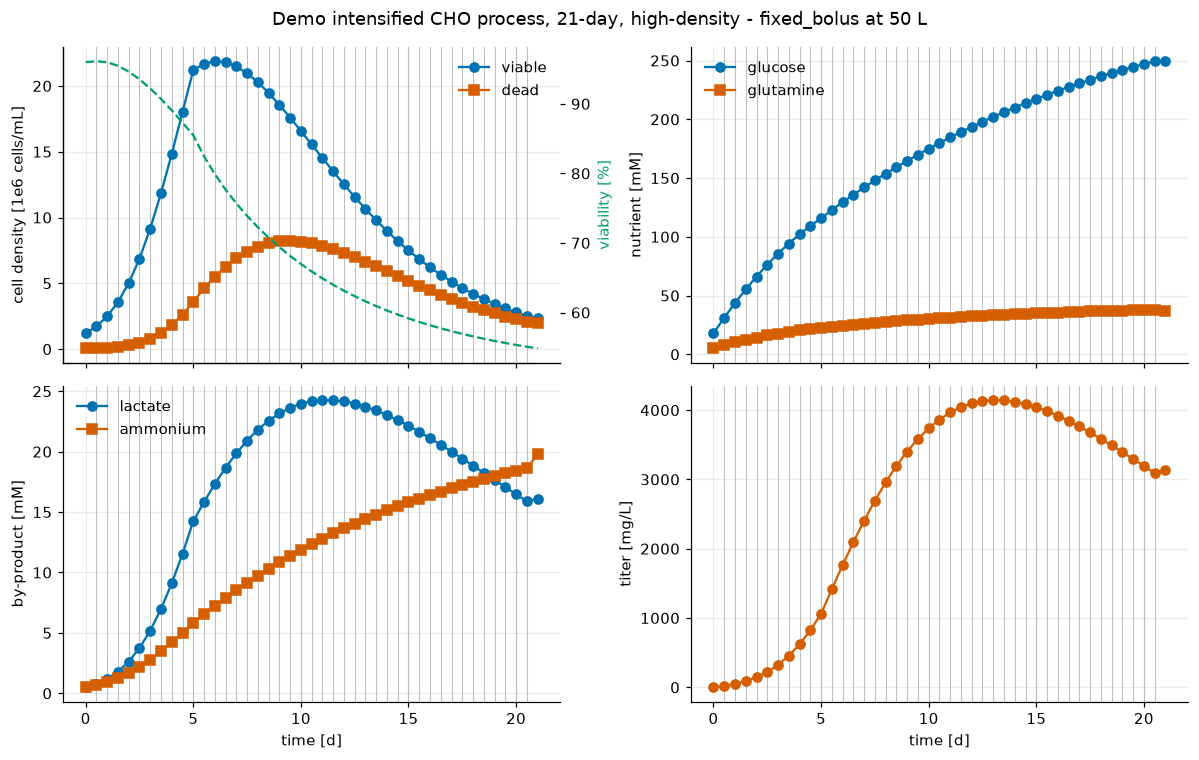

,value
harvest_time_d,9
titer_mg_per_L,"3,403"
harvest_mass_mg,4.095e+05
peak_vcd_1e6_per_mL,21.87
final_viability_percent,69.4
ivcd_1e6_cell_day_per_mL,126.1
qp_pg_per_cell_day,26.99
final_lactate_mM,23.17
final_ammonium_mM,10.84



INFO harvest at day 9.0: 3,403 mg/L x 369.6 L = 409.5 g product
INFO cell-specific productivity 26.99 pg/cell/day (IVCD 126 1e6 cell.d/mL)


In [8]:
scale_L = ask.ask("scale_L", "Working volume at inoculation", float, unit="L", minimum=0.01, maximum=25000)
strategy = ask.ask("feed_strategy", "Feed strategy", str, choices=["glucose_setpoint", "fixed_bolus", "none"])
target_glc = (
    ask.ask("target_glc_mM", "Glucose setpoint to feed back to", float, unit="mM", minimum=1.0, maximum=40.0)
    if strategy == "glucose_setpoint" else None
)
duration_d = ask.ask("duration_d", "Culture duration", float, unit="d", minimum=1, maximum=40)
shift_day = ask.ask("shift_day", "Temperature-shift day (99 = no shift)", float, unit="d", minimum=0)

state = cfg.initial_state(config, volume_L=scale_L)
parameters = cfg.cho_parameters(config)
history = upstream.simulate(
    state, parameters,
    duration_h=duration_d * 24,
    sample_interval_h=float(config["upstream"]["sample_interval_h"]),
    feed_policy=cfg.feed_policy(config, strategy, target_glc),
    shift_time_h=shift_day * 24,
)
metrics = upstream.harvest_metrics(history)

figure = plotting.culture_trajectories(history, title=f"{config['system']['name']} - {strategy} at {scale_L:g} L")
display(figure); plt.close(figure)
display(pd.Series(metrics).to_frame("value"))
print(f"\nINFO harvest at day {metrics['harvest_time_d']:.1f}: "
      f"{metrics['titer_mg_per_L']:,.0f} mg/L x {history['volume'].iloc[-1]:,.1f} L = "
      f"{metrics['harvest_mass_mg'] / 1000:,.1f} g product")
print(f"INFO cell-specific productivity {metrics['qp_pg_per_cell_day']:.2f} pg/cell/day "
      f"(IVCD {metrics['ivcd_1e6_cell_day_per_mL']:,.0f} 1e6 cell.d/mL)")

In [9]:
# Mass balance on glucose over the whole culture: fed in, consumed, what is left.
# This is where dilution bookkeeping errors surface, so it is a check, not a plot.
feed_glc = float(config["upstream"]["feed"]["glc_mM"]) if strategy != "none" else 0.0
CHECKS.append(verification.verify_glucose_balance(history, feed_glc))
display(verification.summarise(CHECKS).tail(3))

,check,status,observed,expected,relative_error,tolerance,note
2,Diafiltration buffer exchange = 1 - exp(-N),PASS,0.9991,0.9991,0,1e-09,"Fully permeable solute, perfectly mixed retentate"
3,Titer is converged at max_step = 1 h,PASS,4.608e-08,0,4.608e-08,0.001,relative to the 0.25 h solution
4,Glucose mass balance over the culture,PASS,0,0,0,1e-06,"fed 95879.822 mmol, consumed 4660.620 mmol (in..."


## 4. Does feedback feeding actually beat a fixed bolus?

A comparison needs replicates on both sides and a stated detection limit; one
run against one run is not a control (ground rules section 1). So both arms are
run with lot-to-lot variation, and the result reports the smallest difference
this design could have resolved.

In [10]:
replicates = ask.ask("strategy_replicates", "Replicate batches per feed strategy", int,
                     minimum=2, maximum=20, default=5,
                     help="2 is the minimum for a comparison; more narrows the detection limit")

generator = np.random.default_rng(SEED + 7)
arms = {}
for arm in ["glucose_setpoint", "fixed_bolus"]:
    harvests = []
    for replicate in range(replicates):
        sigma = np.sqrt(np.log(1.0 + 0.08**2))
        perturbed = upstream.CHOParameters(**{
            **parameters.__dict__,
            "mu_max_per_h": parameters.mu_max_per_h * generator.lognormal(-0.5 * sigma**2, sigma),
            "qp_beta_mg_per_1e9cells_h": parameters.qp_beta_mg_per_1e9cells_h * generator.lognormal(-0.5 * sigma**2, sigma),
        })
        run = upstream.simulate(
            cfg.initial_state(config, volume_L=scale_L), perturbed,
            duration_h=duration_d * 24, sample_interval_h=float(config["upstream"]["sample_interval_h"]),
            feed_policy=cfg.feed_policy(config, arm, target_glc), shift_time_h=shift_day * 24,
        )
        harvests.append(upstream.harvest_metrics(run)["harvest_mass_mg"] / 1000.0)
    arms[arm] = np.array(harvests)
    print(f"  {arm}: {np.mean(harvests):,.1f} +/- {np.std(harvests, ddof=1):,.1f} g (n = {replicates})")

result = quality.comparability(arms["glucose_setpoint"], arms["fixed_bolus"], name="feed strategy")
display(pd.Series(result).to_frame("value"))
print(f"\n{'INFO' if result['significant'] else 'WARN'} {result['verdict']}")
if not result["significant"] and abs(result["difference"]) < result["min_detectable_difference"]:
    print("     The difference is smaller than this design can resolve. That is not evidence of no effect:")
    print(f"     raise the replicates above {replicates} to resolve it.")

  strategy_replicates = 5   (default (no keyboard))


  glucose_setpoint: 389.1 +/- 45.6 g (n = 5)


  fixed_bolus: 466.7 +/- 77.1 g (n = 5)


,value
name,feed strategy
mean_a,389.1
mean_b,466.7
n_a,5
n_b,5
difference,-77.59
cohens_d,-1.226
p_value,0.09705
significant,False
min_detectable_difference,80.7



WARN difference -77.6 (p = 0.097); this design could detect 80.7 at 80% power
     The difference is smaller than this design can resolve. That is not evidence of no effect:
     raise the replicates above 5 to resolve it.


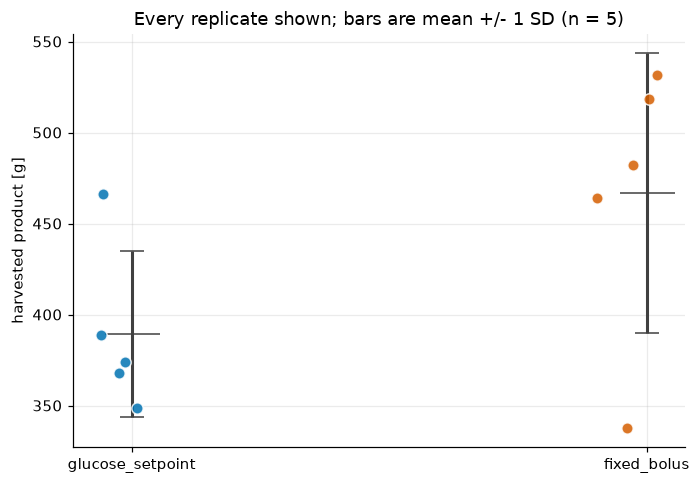

In [11]:
figure, axis = plt.subplots(figsize=(6.5, 4.5))
positions = [0, 1]
for position, (arm, values) in zip(positions, arms.items()):
    axis.scatter(np.full(values.size, position) + generator.normal(0, 0.035, values.size), values,
                 s=55, alpha=0.85, color=plotting.OKABE_ITO[position], edgecolor="white", zorder=3)
    axis.errorbar(position, values.mean(), yerr=values.std(ddof=1), fmt="_", markersize=36,
                  color="0.25", capsize=8, linewidth=2, zorder=2)
axis.set_xticks(positions); axis.set_xticklabels(list(arms))
axis.set_ylabel("harvested product [g]")
axis.set_title(f"Every replicate shown; bars are mean +/- 1 SD (n = {replicates})")
display(figure); plt.close(figure)

## 5. The campaign: what does batch-to-batch variation look like?

The campaign from section 2 is the training data for every model that follows.
Showing all the runs, not just their mean, is what makes the spread legible.

,batch_id,clone,feed_strategy,scale_L,seed_density_1e6_per_mL,mu_max_per_h,qp_beta_mg_per_1e9cells_h,harvest_time_d,titer_mg_per_L,harvest_mass_mg,peak_vcd_1e6_per_mL,final_viability_percent,ivcd_1e6_cell_day_per_mL,qp_pg_per_cell_day,final_lactate_mM,final_ammonium_mM
0,B001,A,glucose_setpoint,5,0.395,0.04067,1.27,15.5,"6,295",3.227e+04,18.19,69.83,160.4,39.24,19,4.528
1,B002,B,fixed_bolus,50,0.3494,0.03992,1.696,17.5,"8,136",1.356e+06,19.46,69.77,223.3,36.44,29.55,10.29
2,B003,A,glucose_setpoint,500,0.4062,0.03408,1.418,13,"4,314",2.157e+06,12.6,69.42,97.08,44.44,14.31,4.102
3,B004,B,fixed_bolus,5,0.3522,0.03987,1.788,15.5,"6,983",1.014e+05,17.36,69.51,172.8,40.41,25.53,9.276
4,B005,A,glucose_setpoint,50,0.3872,0.04095,1.349,21,"8,529",4.426e+05,18.78,69.95,204.6,41.68,21.17,4.809
5,B006,B,fixed_bolus,500,0.4136,0.03731,1.871,15,"5,897",8.275e+06,14.17,69.65,139.1,42.38,20.68,8.582
6,B007,A,glucose_setpoint,5,0.4121,0.03868,1.356,12,"4,645",2.342e+04,15.93,69.44,110.8,41.94,16.06,4.187
7,B008,B,fixed_bolus,50,0.4226,0.0318,1.834,17,"3,755",6.047e+05,8.161,69.57,97.16,38.65,12.52,8.407
8,B009,A,glucose_setpoint,500,0.4025,0.03989,1.126,12,"4,032",2.039e+06,16.8,69.56,116.1,34.72,16.6,4.237


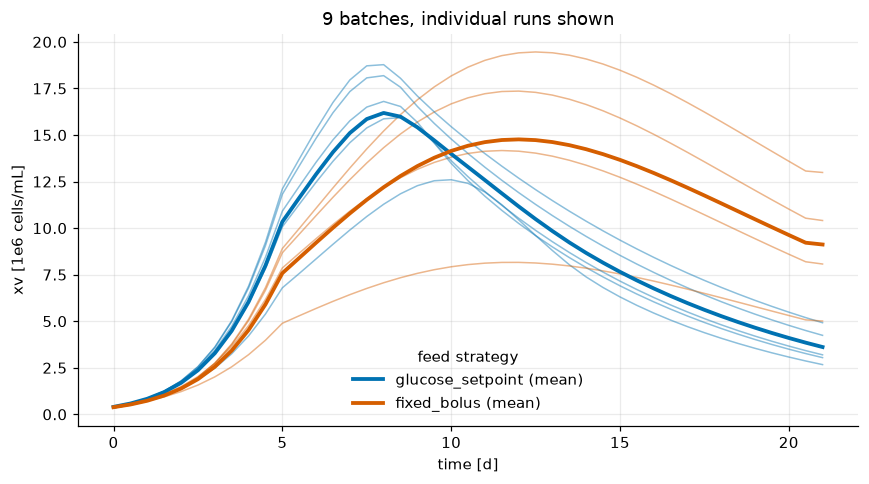

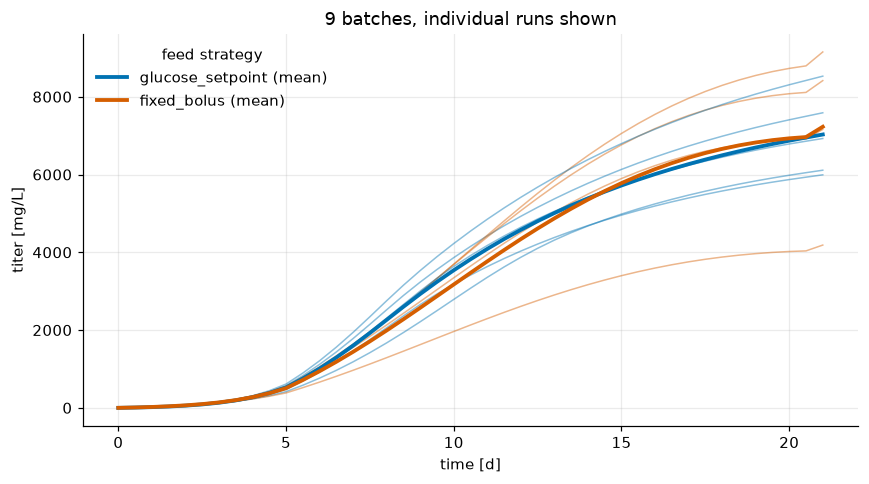

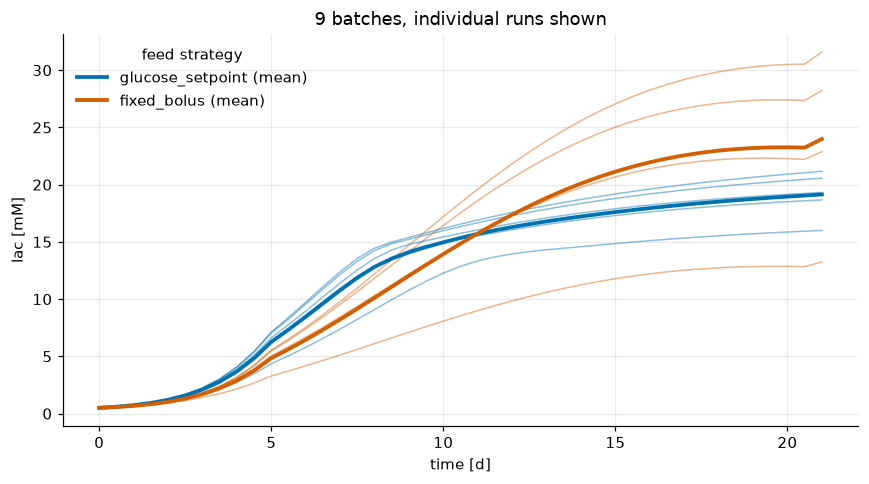

In [12]:
if batches is None:
    print("INFO the loaded data has no per-batch summary; deriving one from the samples")
    grouped = []
    for batch_id, frame in samples.groupby("batch_id"):
        frame = frame.sort_values("time_h")
        row = {"batch_id": batch_id}
        if {"xv", "titer", "volume", "time_d"} <= set(frame.columns):
            row.update(upstream.harvest_metrics(frame))
        grouped.append(row)
    batches = pd.DataFrame(grouped)

display(batches.head(10))
if "feed_strategy" in samples.columns:
    for column, unit in [("xv", "1e6 cells/mL"), ("titer", "mg/L"), ("lac", "mM")]:
        if column in samples.columns:
            figure = plotting.campaign_overlay(samples, column, unit)
            display(figure); plt.close(figure)

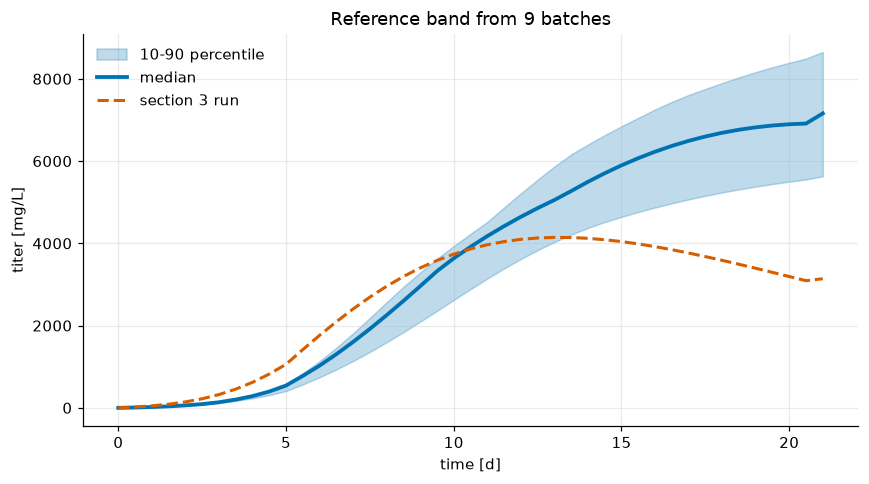

In [13]:
# A reference band across batches: the median trajectory with a 10-90 percentile
# envelope. A new run outside the band is a candidate deviation.
if "batch_id" in samples.columns and samples["batch_id"].nunique() >= 3 and "titer" in samples.columns:
    band = quality.golden_batch(samples, "titer")
    figure, axis = plt.subplots(figsize=(8, 4.5))
    axis.fill_between(band["time_d"], band["p10"], band["p90"], alpha=0.25,
                      color=plotting.OKABE_ITO[0], label="10-90 percentile")
    axis.plot(band["time_d"], band["median"], color=plotting.OKABE_ITO[0], linewidth=2.5, label="median")
    axis.plot(history["time_d"], history["titer"], color=plotting.OKABE_ITO[1], linewidth=2,
              linestyle="--", label="section 3 run")
    axis.set_xlabel("time [d]"); axis.set_ylabel("titer [mg/L]")
    axis.set_title(f"Reference band from {int(band['n_batches'].max())} batches")
    axis.legend(frameon=False)
    display(figure); plt.close(figure)
else:
    print("INFO fewer than 3 batches, or no titer column: no reference band")

## 6. Sensitivity: which parameters actually move the titer?

Variance-based global sensitivity (Sobol) over the ranges in
`[upstream.sensitivity]`. First-order `S1` is the variance a parameter explains
on its own; total `ST` includes its interactions. A large gap between them means
the parameter matters mostly through interaction, which a one-at-a-time study
would miss entirely.

Cost: `n * (2D + 2)` model runs. At 64 base samples and 6 parameters that is 896
cultures, about a minute. The confidence intervals widen if you lower it, which
is the honest trade.

  run_sensitivity = True   (default (no keyboard))
  sobol_base_samples = 64   (default (no keyboard))


  200/512 evaluations


  400/512 evaluations


  512 model runs in 38.9 s


,parameter,S1,S1_conf,ST,ST_conf
0,mu_max_per_h,0.4586,0.2319,0.4848,0.1703
1,kd_amm_max_per_h,0.2696,0.19,0.2858,0.1128
2,qp_beta_mg_per_1e9cells_h,0.1933,0.1119,0.2195,0.07763
3,y_x_glc_1e9cells_per_mmol,0.01734,0.04467,0.01415,0.007637
4,ki_lac_mM,0.01592,0.03993,0.0132,0.006217
5,ks_glc_mM,0.00344,0.00917,0.0006831,0.0004103


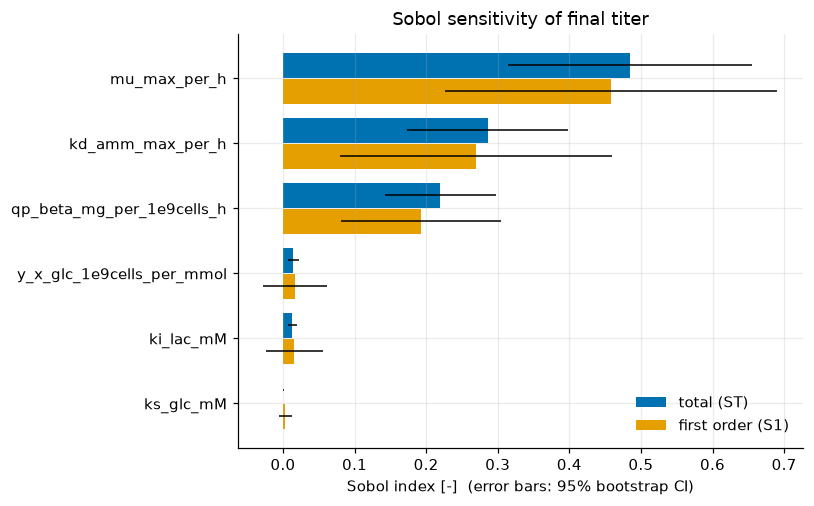


INFO mu_max_per_h dominates: ST = 0.48 (48% of the titer variance, including interactions)
INFO largest ST - S1 gap is 0.03: the parameters act mostly independently over these ranges
INFO negligible over these ranges (ST < 0.02): y_x_glc_1e9cells_per_mmol, ki_lac_mM, ks_glc_mM


In [14]:
run_sensitivity = ask.ask("run_sensitivity", "Run the Sobol sensitivity study?", bool)

if run_sensitivity:
    base_samples = ask.ask("sobol_base_samples", "Saltelli base samples (power of 2)", int,
                           choices=["16", "32", "64", "128", "256"],
                           help="model runs = n * (2D + 2); 64 with 6 parameters = 896 runs")
    bounds = {k: tuple(v) for k, v in config["upstream"]["sensitivity"].items()}

    def titer_from(sample):
        perturbed = cfg.cho_parameters(config, overrides=sample)
        run = upstream.simulate(
            cfg.initial_state(config, volume_L=scale_L), perturbed,
            duration_h=duration_d * 24, sample_interval_h=48.0,  # coarser sampling: only the endpoint is used
            feed_policy=cfg.feed_policy(config, strategy, target_glc), shift_time_h=shift_day * 24,
            max_step_h=2.0,
        )
        return float(run["titer"].iloc[-1])

    started = time.perf_counter()
    indices, record = uq.sobol_indices(titer_from, bounds, n_samples=int(base_samples), seed=SEED,
                                       progress_every=200)
    print(f"  {record['n_evaluations']} model runs in {time.perf_counter() - started:.1f} s")
    display(indices)
    figure = plotting.sensitivity_bars(indices, "Sobol sensitivity of final titer")
    display(figure); plt.close(figure)

    dominant = indices.iloc[0]
    interaction = float((indices["ST"] - indices["S1"]).max())
    print(f"\nINFO {dominant['parameter']} dominates: ST = {dominant['ST']:.2f} "
          f"({dominant['ST'] * 100:.0f}% of the titer variance, including interactions)")
    print(f"INFO largest ST - S1 gap is {interaction:.2f}: "
          + ("interactions matter, so vary parameters jointly, not one at a time"
             if interaction > 0.05 else "the parameters act mostly independently over these ranges"))
    negligible = indices[indices["ST"] < 0.02]["parameter"].tolist()
    if negligible:
        print(f"INFO negligible over these ranges (ST < 0.02): {', '.join(negligible)}")
else:
    indices = None
    print("INFO sensitivity skipped")

## 7. Uncertainty: an interval, not a single number

Propagate the uncertainty in the inputs you are least sure of through to the
harvest. Rates and potencies are given lognormal priors because a normal with a
wide CV puts mass below zero, and a negative rate constant is not a thing.

The output is a median with a 5-95% interval. A single trajectory is not a
result for a model with uncertain inputs (ground rules section 3).

  run_monte_carlo = True   (default (no keyboard))
  monte_carlo_samples = 120   (default (no keyboard))
  input_cv = 0.1   (default (no keyboard))



INFO harvested product 439 [284, 679] g (median [5-95%], n = 120, input CV = 10%)
INFO relative spread 27.2% of the mean


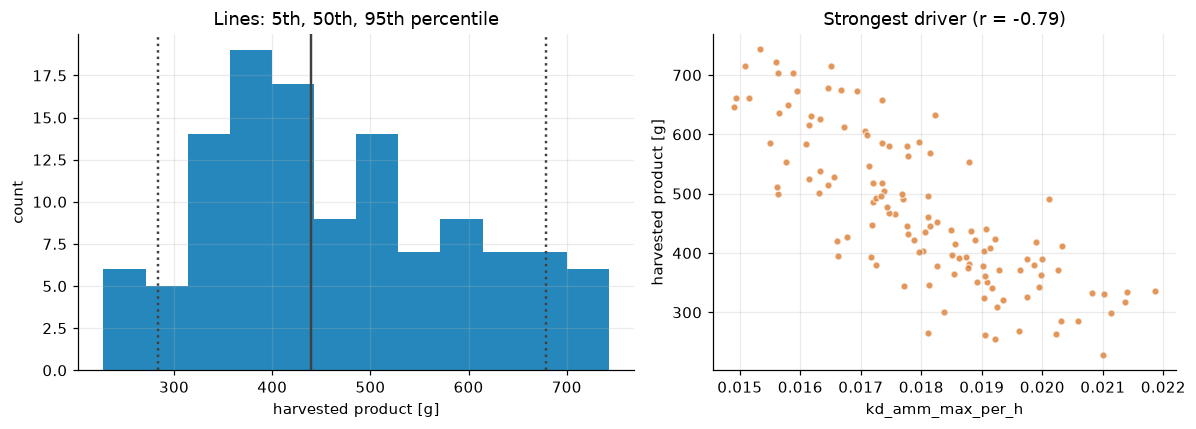

In [15]:
run_mc = ask.ask("run_monte_carlo", "Propagate input uncertainty to the harvest?", bool)

if run_mc:
    draws = ask.ask("monte_carlo_samples", "Monte Carlo samples", int, minimum=30, maximum=2000)
    cv = ask.ask("input_cv", "Coefficient of variation on the uncertain inputs", float,
                 minimum=0.01, maximum=0.5, default=0.10,
                 help="0.10 is lot-to-lot scale; 0.25 is cell-line scale")

    nominal = cfg.cho_parameters(config)
    distributions = {
        "mu_max_per_h": ("lognormal", nominal.mu_max_per_h, cv),
        "qp_beta_mg_per_1e9cells_h": ("lognormal", nominal.qp_beta_mg_per_1e9cells_h, cv),
        "y_x_glc_1e9cells_per_mmol": ("lognormal", nominal.y_x_glc_1e9cells_per_mmol, cv),
        "kd_amm_max_per_h": ("lognormal", nominal.kd_amm_max_per_h, cv),
    }

    def harvest_mass_g(sample):
        run = upstream.simulate(
            cfg.initial_state(config, volume_L=scale_L), cfg.cho_parameters(config, overrides=sample),
            duration_h=duration_d * 24, sample_interval_h=24.0,
            feed_policy=cfg.feed_policy(config, strategy, target_glc), shift_time_h=shift_day * 24,
            max_step_h=2.0,
        )
        return upstream.harvest_metrics(run)["harvest_mass_mg"] / 1000.0

    table, summary = uq.monte_carlo(harvest_mass_g, distributions, n_samples=int(draws), seed=SEED)
    print(f"\nINFO harvested product {uq.interval_string(summary, 'g')} "
          f"(median [5-95%], n = {summary['n_samples']}, input CV = {cv:.0%})")
    print(f"INFO relative spread {summary['sd'] / summary['mean']:.1%} of the mean")

    figure, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.2, 1]})
    axes[0].hist(table["output"], bins=max(12, int(np.sqrt(len(table)))), color=plotting.OKABE_ITO[0], alpha=0.85)
    for quantile, style in [("q05", ":"), ("q50", "-"), ("q95", ":")]:
        axes[0].axvline(summary[quantile], color="0.25", linestyle=style, linewidth=1.6)
    axes[0].set_xlabel("harvested product [g]"); axes[0].set_ylabel("count")
    axes[0].set_title("Lines: 5th, 50th, 95th percentile")
    strongest = max(distributions, key=lambda k: abs(np.corrcoef(table[k], table["output"])[0, 1]))
    axes[1].scatter(table[strongest], table["output"], s=22, alpha=0.65,
                    color=plotting.OKABE_ITO[1], edgecolor="white")
    axes[1].set_xlabel(strongest); axes[1].set_ylabel("harvested product [g]")
    axes[1].set_title(f"Strongest driver (r = {np.corrcoef(table[strongest], table['output'])[0, 1]:+.2f})")
    display(figure); plt.close(figure)
else:
    summary = None
    print("INFO uncertainty propagation skipped; results below are single trajectories")

## 8. Can a data-driven model predict the KPI?

The question the review literature keeps returning to: given process
descriptors, can PLS, a random forest or a Gaussian process predict a batch KPI?

Two rules make the answer meaningful.

1. **Grouped splits.** Cross-validation is by batch. A random split over time
   points from the same run leaks nearly identical neighbours into the test set
   and flatters every model.
2. **A baseline beside every score.** The mean predictor is reported next to the
   model. `skill_vs_mean <= 0` means the model is not evidence of anything,
   however good its R² looks.

  kpi_target = titer_mg_per_L   (default (no keyboard))
  model_features = seed_density_1e6_per_mL, peak_vcd_1e6_per_mL, ivcd_1e6_cell_day_per_mL, final_lactate_mM   (default (no keyboard))
  batch_model = random_forest   (default (no keyboard))

9 batches, 4 features



INFO random_forest: RMSE 1.08e+03 vs mean-predictor 1.68e+03 (grouped 5-fold) - beats the baseline


,value
rmse,"1,075"
nrmse_percent,22.52
r2,0.5902
n_test,9
rmse_mean_baseline,"1,680"
skill_vs_mean,0.5902


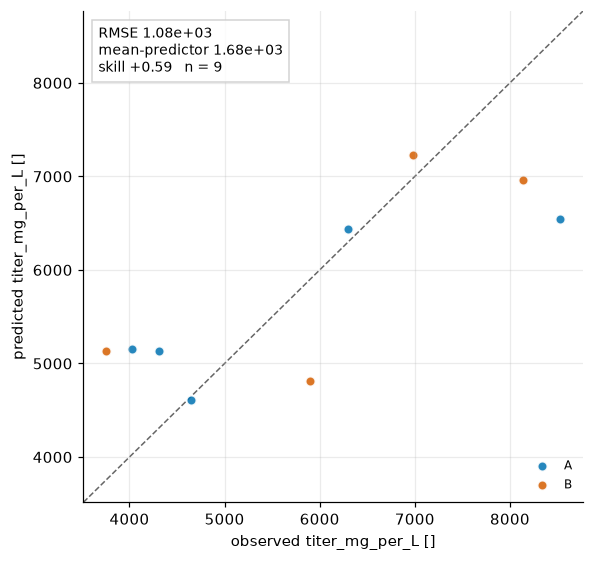

In [16]:
available_features = [c for c in batches.columns
                      if batches[c].dtype.kind in "fi" and batches[c].notna().all()]
target = ask.ask("kpi_target", "Which KPI should the model predict?", str,
                 choices=[c for c in ["titer_mg_per_L", "harvest_mass_mg", "peak_vcd_1e6_per_mL",
                                      "qp_pg_per_cell_day"] if c in available_features])
features = ask.ask("model_features", "Which features should it use?", str,
                   choices=[c for c in available_features if c != target], multiple=True,
                   help="fewer than the batch count, or the fit is underdetermined (the Low-N problem)")
chosen = ask.ask("batch_model", "Which model?", str, choices=list(models.MODEL_CHOICES))

print(f"\n{len(batches)} batches, {len(features)} features"
      + ("   WARN samples <= features: the fit will be underdetermined" if len(batches) <= len(features) else ""))

fitted = models.fit_batch_model(batches, list(features), target, model=chosen, seed=SEED)
print(f"\nINFO {fitted.summary_line()}")
display(pd.Series(fitted.scores).to_frame("value"))
figure = plotting.parity(fitted.observed, fitted.predictions, label=target, unit="",
                         scores=fitted.scores, groups=batches.loc[batches.index, "clone"] if "clone" in batches else None)
display(figure); plt.close(figure)

if not fitted.beats_baseline():
    FINDINGS.append(f"the {chosen} model does not beat the mean predictor for {target}")
    print(f"WARN {FINDINGS[-1]}. Reporting it as a result would be misleading.")

In [17]:
# Every model on the same split, so the comparison is like for like.
comparison = {}
for name in models.MODEL_CHOICES:
    try:
        candidate = models.fit_batch_model(batches, list(features), target, model=name, seed=SEED)
        comparison[name] = candidate.scores
    except ValueError as error:
        print(f"INFO {name} skipped: {error}")
table = evaluation.report_table(comparison)[
    ["rmse", "rmse_mean_baseline", "skill_vs_mean", "r2", "nrmse_percent", "n_test"]
]
display(table.sort_values("rmse"))
beaten = table[table["skill_vs_mean"] > 0]
print(f"\nINFO {len(beaten)} of {len(table)} models beat the mean predictor out of fold")
if beaten.empty:
    FINDINGS.append(f"no model beats the mean predictor for {target} on {len(batches)} batches")
    print(f"WARN {FINDINGS[-1]} - this is the Low-N problem, not a modelling choice")

,rmse,rmse_mean_baseline,skill_vs_mean,r2,nrmse_percent,n_test
ridge,786.5,"1,680",0.7808,0.7808,16.47,9
pls,858.5,"1,680",0.7388,0.7388,17.98,9
random_forest,"1,075","1,680",0.5902,0.5902,22.52,9
gaussian_process,"1,396","1,680",0.3098,0.3098,29.23,9



INFO 4 of 4 models beat the mean predictor out of fold


## 9. Soft sensor: can a spectrum replace an offline assay?

Raman plus PLS is the workhorse of in-line bioprocess monitoring. The spectra
here are simulated from the known concentrations, with a broad fluorescence
background and detector noise on top - that background is exactly what makes
real Raman calibration hard (Gautam et al. 2015).

Two things are checked rather than assumed:

- **Does preprocessing help?** The calibration is run with and without baseline
  correction and the errors are compared. Preprocessing has to earn its place.
- **How many components?** Chosen on out-of-fold error across the whole scan,
  never on the fit, and the whole scan is shown rather than one cut
  (ground rules section 1: never tune a threshold against the answer).

  run_soft_sensor = True   (default (no keyboard))
  soft_sensor_target = glucose_mM   (default (no keyboard))
  soft_sensor_components = 5   (default (no keyboard))
  baseline_correct_spectra = True   (default (no keyboard))
WARN SYNTHETIC spectra. They show the calibration pipeline recovers a known answer.


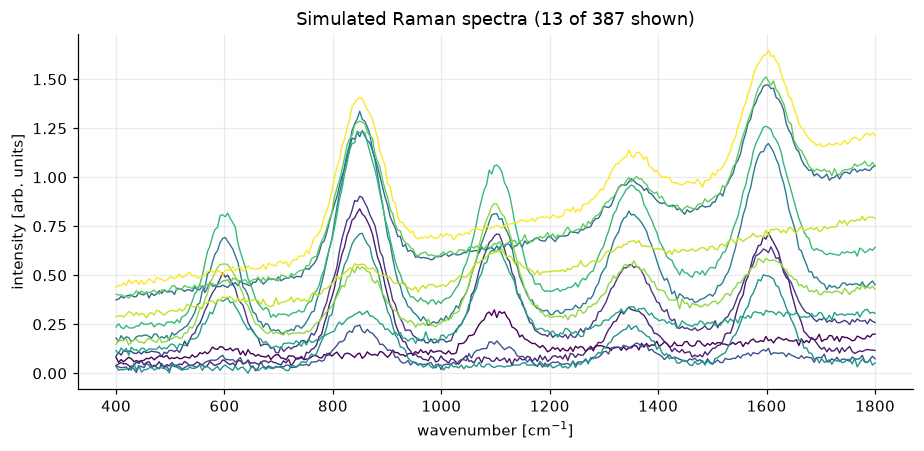

  raw: RMSE 1.72 vs mean-predictor 60 (grouped 5-fold)
  baseline-corrected: RMSE 3.89 vs mean-predictor 60 (grouped 5-fold)

INFO baseline correction changes RMSE by -126.4% - it does not help here, so it is not assumed


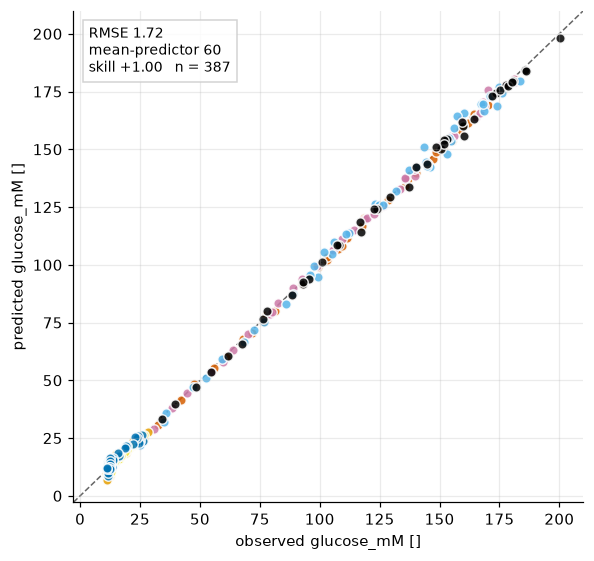

In [18]:
run_soft_sensor = ask.ask("run_soft_sensor", "Build a Raman soft sensor?", bool)

if run_soft_sensor:
    analytes = [c for c in ["glucose_mM", "lactate_mM", "glutamine_mM", "ammonium_mM", "titer_mg_per_L"]
                if c in samples.columns]
    if len(analytes) < 2:
        raise ValueError(f"need at least 2 analyte columns to simulate spectra, found {analytes}")
    sensor_target = ask.ask("soft_sensor_target", "Which analyte should the sensor predict?", str, choices=analytes)
    components = ask.ask("soft_sensor_components", "PLS components", int, minimum=1, maximum=20)
    correct = ask.ask("baseline_correct_spectra", "Apply baseline correction before calibrating?", bool)

    spectra, wavenumbers, spectra_truth = models.simulate_spectra(samples[analytes], seed=SEED)
    print(f"WARN {spectra_truth['warning']}")
    figure = plotting.spectra_plot(wavenumbers, spectra)
    display(figure); plt.close(figure)

    y = samples[sensor_target].to_numpy()
    groups = samples["batch_id"].to_numpy()
    variants = {"raw": spectra}
    if correct:
        variants["baseline-corrected"] = models.baseline_correct(spectra)

    sensors = {}
    for label, matrix in variants.items():
        sensor = models.fit_soft_sensor(matrix, y, groups, n_components=int(components), seed=SEED)
        sensors[label] = sensor
        print(f"  {label}: RMSE {sensor.scores['rmse']:.3g} vs mean-predictor "
              f"{sensor.scores['rmse_mean_baseline']:.3g} ({sensor.split})")

    best_label = min(sensors, key=lambda k: sensors[k].scores["rmse"])
    best = sensors[best_label]
    if len(sensors) > 1:
        improvement = 1 - sensors["baseline-corrected"].scores["rmse"] / sensors["raw"].scores["rmse"]
        print(f"\nINFO baseline correction changes RMSE by {improvement:+.1%} - "
              + ("it earns its place" if improvement > 0.02 else "it does not help here, so it is not assumed"))
    figure = plotting.parity(best.observed, best.predictions, label=sensor_target,
                             unit="", scores=best.scores, groups=groups)
    display(figure); plt.close(figure)
else:
    best = None
    print("INFO soft sensor skipped")

,n_components,rmse,rmse_mean_baseline,skill_vs_mean
0,1,53.39,59.95,0.2069
1,2,8.925,59.95,0.9778
2,3,4.238,59.95,0.995
3,5,1.716,59.95,0.9992
4,8,1.215,59.95,0.9996
5,12,1.554,59.95,0.9993


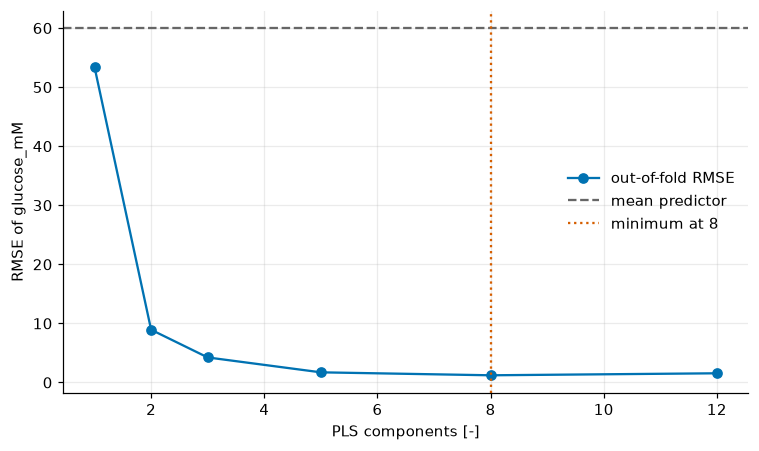

WARN you chose 5 components; the out-of-fold minimum is at 8


In [19]:
if run_soft_sensor:
    # The component scan, shown whole. The minimum of the out-of-fold curve is
    # the choice; the rise past it is overfitting made visible.
    scan = models.choose_components(variants[best_label], y, groups)
    display(scan)
    figure, axis = plt.subplots(figsize=(7, 4.2))
    axis.plot(scan["n_components"], scan["rmse"], marker="o", label="out-of-fold RMSE")
    axis.axhline(scan["rmse_mean_baseline"].iloc[0], color="0.4", linestyle="--",
                 label="mean predictor")
    optimum = int(scan.loc[scan["rmse"].idxmin(), "n_components"])
    axis.axvline(optimum, color=plotting.OKABE_ITO[1], linestyle=":", label=f"minimum at {optimum}")
    axis.set_xlabel("PLS components [-]"); axis.set_ylabel(f"RMSE of {sensor_target}")
    axis.legend(frameon=False)
    display(figure); plt.close(figure)
    if optimum != int(components):
        print(f"WARN you chose {int(components)} components; the out-of-fold minimum is at {optimum}")
    if not best.beats_baseline():
        FINDINGS.append(f"the soft sensor for {sensor_target} does not beat the mean predictor")
        print(f"WARN {FINDINGS[-1]}")

## 10. Hybrid: does a data-driven rate on top of the mechanism help?

The serial hybrid structure of Narayanan et al. (2019),
doi:10.1002/bit.27097: mass balances stay mechanistic, and a data-driven part
supplies a rate the mechanism does not predict. Here it learns a *multiplier* on
the specific productivity, so a model that learns nothing predicts 1.0 and the
mechanistic model is recovered unchanged. That makes "did the ML part help?" a
question with an answer rather than a matter of taste.

INFO random_forest: RMSE 0.0886 vs mean-predictor 0.0714 (grouped 5-fold) - does NOT beat the baseline

INFO mechanism alone (ratio = 1): RMSE 0.0722
INFO mechanism + ML correction:    RMSE 0.0886 (out of fold)
WARN the hybrid correction does not improve on the mechanistic model alone - keep the mechanistic model, which extrapolates better


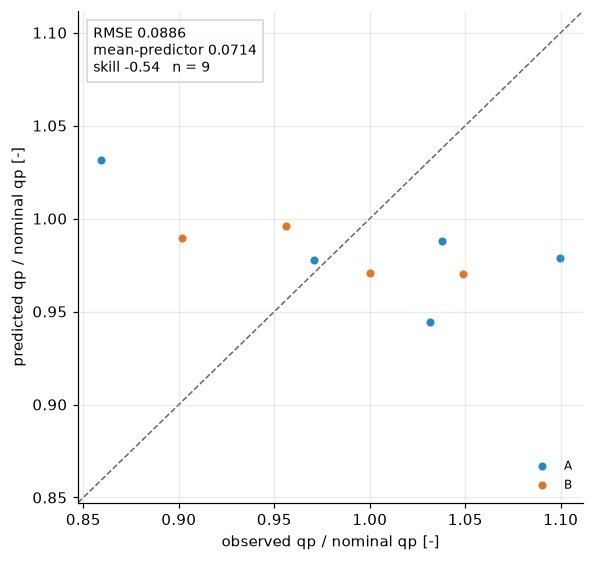

In [20]:
if "qp_pg_per_cell_day" in batches.columns and len(batches) >= 6:
    nominal_qp = float(batches["qp_pg_per_cell_day"].median())
    table = batches.copy()
    table["qp_nominal_pg_per_cell_day"] = nominal_qp

    hybrid_features = [f for f in ["seed_density_1e6_per_mL", "peak_vcd_1e6_per_mL",
                                   "final_lactate_mM", "final_ammonium_mM", "ivcd_1e6_cell_day_per_mL"]
                       if f in table.columns]
    hybrid = models.hybrid_productivity_correction(table, hybrid_features, seed=SEED)
    print(f"INFO {hybrid.summary_line()}")

    # The honest comparison: mechanism alone (ratio = 1) against mechanism + ML.
    ratio = table["qp_pg_per_cell_day"] / nominal_qp
    mechanistic_only = evaluation.rmse(ratio, np.ones_like(ratio))
    print(f"\nINFO mechanism alone (ratio = 1): RMSE {mechanistic_only:.4f}")
    print(f"INFO mechanism + ML correction:    RMSE {hybrid.scores['rmse']:.4f} (out of fold)")
    if hybrid.scores["rmse"] < mechanistic_only:
        print(f"INFO the data-driven part reduces the error by {1 - hybrid.scores['rmse'] / mechanistic_only:.1%}")
    else:
        FINDINGS.append("the hybrid correction does not improve on the mechanistic model alone")
        print(f"WARN {FINDINGS[-1]} - keep the mechanistic model, which extrapolates better")

    figure = plotting.parity(hybrid.observed, hybrid.predictions,
                             label="qp / nominal qp", unit="-", scores=hybrid.scores,
                             groups=table["clone"] if "clone" in table else None)
    display(figure); plt.close(figure)
else:
    print("INFO hybrid section needs at least 6 batches with a productivity column; skipped")

## 11. Capture chromatography: DBC, residence time, cycles

Protein A capture, simulated with a lumped kinetic model: tanks in series,
Langmuir equilibrium, one lumped mass-transfer coefficient (the form used for
breakthrough prediction by Narayanan et al. 2021,
doi:10.1016/j.chroma.2021.462248).

The number the step is sized on is `DBC10` - the load, per litre of resin, at
which 10% of the product starts coming out the bottom. Residence time is the
lever: run faster and the front has less time to transfer into the bead, so the
curve breaks earlier and the usable capacity falls.

**A modelling caveat worth knowing.** Dispersion here is set by the number of
tanks, so the tank count is a *model parameter*, not a mesh to refine. The cell
below shows what changing it does, which is why it is reported rather than
quietly tuned.

  capture_velocity_cm_per_h = 250.0 cm/h   (default (no keyboard))
  capture_bed_height_cm = 20.0 cm   (default (no keyboard))
  load_fraction_of_dbc = 0.75   (default (no keyboard))
  breakthrough_fraction = 0.1   (default (no keyboard))
INFO feed to capture: 380.8 g at 1.03 g/L (clarification yield 93%)


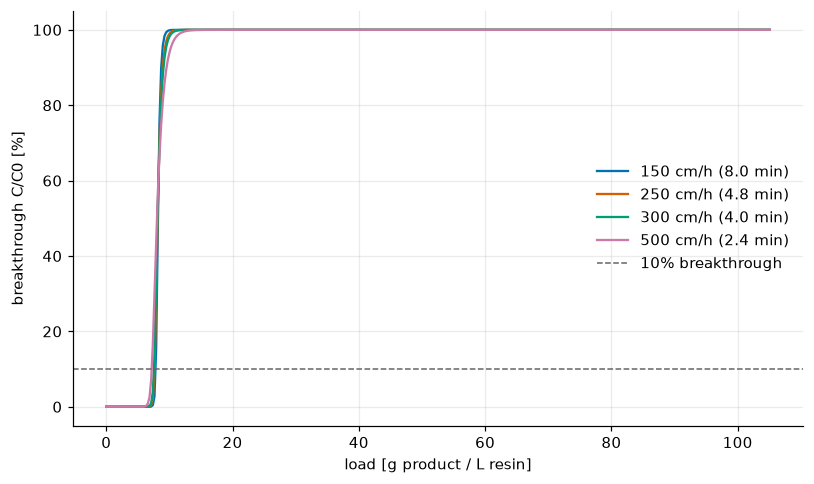

,operation,DBC10_g_per_L_resin
0,150 cm/h (8.0 min),7.792
1,250 cm/h (4.8 min),7.65
2,300 cm/h (4.0 min),7.539
3,500 cm/h (2.4 min),7.191


In [21]:
velocity = ask.ask("capture_velocity_cm_per_h", "Load velocity", float, unit="cm/h", minimum=30, maximum=1000)
bed_height = ask.ask("capture_bed_height_cm", "Bed height", float, unit="cm", minimum=5, maximum=40)
load_fraction = ask.ask("load_fraction_of_dbc", "Load to what fraction of DBC10?", float, minimum=0.3, maximum=1.0)
breakthrough_at = ask.ask("breakthrough_fraction", "Breakthrough fraction to size on", float,
                          minimum=0.01, maximum=0.5, help="0.10 is the usual choice")

column = cfg.capture_column(config, bed_height_cm=bed_height)
operation = config["downstream"]["capture"]["operation"]

harvest_g = metrics["harvest_mass_mg"] / 1000.0
clarified_g = harvest_g * float(config["downstream"]["clarification_yield"])
feed_g_per_L = clarified_g / history["volume"].iloc[-1]
print(f"INFO feed to capture: {clarified_g:,.1f} g at {feed_g_per_L:.2f} g/L "
      f"(clarification yield {config['downstream']['clarification_yield']:.0%})")

# Breakthrough across a range of residence times: the engineering trade-off.
curves = {}
for candidate in sorted({velocity, 150.0, 300.0, 500.0}):
    curve = downstream.breakthrough_curve(column, resin, feed_g_per_L, candidate, load_cv=120.0)
    residence = column.residence_time_min(candidate)
    curves[f"{candidate:.0f} cm/h ({residence:.1f} min)"] = curve
figure = plotting.breakthrough(curves, breakthrough_at)
display(figure); plt.close(figure)

rows = []
for label, curve in curves.items():
    try:
        rows.append({"operation": label,
                     f"DBC{int(breakthrough_at * 100)}_g_per_L_resin": downstream.dynamic_binding_capacity(curve, breakthrough_at)})
    except ValueError as error:
        print(f"WARN {label}: {error}")
display(pd.DataFrame(rows))

In [22]:
# Tanks in series sets the dispersion, so it is a model parameter. Showing its
# effect is more honest than picking a value that makes the curve look right.
tank_rows = []
for tanks in [10, 20, 30, 50, 80]:
    curve = downstream.breakthrough_curve(column, resin, feed_g_per_L, velocity, load_cv=120.0, n_tanks=tanks)
    tank_rows.append({"n_tanks": tanks,
                      "DBC10_g_per_L_resin": downstream.dynamic_binding_capacity(curve, 0.10)})
tank_table = pd.DataFrame(tank_rows)
tank_table["change_vs_30_percent"] = 100 * (
    tank_table["DBC10_g_per_L_resin"] / tank_table.loc[tank_table["n_tanks"] == 30, "DBC10_g_per_L_resin"].iloc[0] - 1
)
display(tank_table)
spread = float(tank_table["change_vs_30_percent"].abs().max())
print(f"INFO DBC10 moves by up to {spread:.1f}% across 10-80 tanks.")
print("     That spread is model uncertainty, not numerical error: in a real study the tank")
print("     count is fitted to a measured breakthrough curve, and that fit is the validation.")

,n_tanks,DBC10_g_per_L_resin,change_vs_30_percent
0,10,7.377,-3.559
1,20,7.567,-1.083
2,30,7.65,0
3,50,7.686,0.4715
4,80,7.706,0.7314


INFO DBC10 moves by up to 3.6% across 10-80 tanks.
     That spread is model uncertainty, not numerical error: in a real study the tank
     count is fitted to a measured breakthrough curve, and that fit is the validation.


In [23]:
capture = downstream.capture_step(
    column, resin, feed_g_per_L, float(history["volume"].iloc[-1]), velocity,
    load_fraction_of_dbc=load_fraction,
    elution_recovery=float(operation["elution_recovery"]),
    hcp_log_reduction=float(operation["hcp_log_reduction"]),
    dna_log_reduction=float(operation["dna_log_reduction"]),
    aggregate_removal_fraction=float(operation["aggregate_removal_fraction"]),
    leached_protein_a_ng_per_mg=float(operation["leached_protein_a_ng_per_mg"]),
)
display(pd.Series(capture).to_frame("value"))
print(f"\nINFO {capture['cycles']} cycle(s) on a {column.volume_L:.1f} L column at "
      f"{capture['residence_time_min']:.1f} min residence time")
print(f"INFO step yield {capture['yield_fraction']:.1%} "
      f"(load {capture['load_yield_fraction']:.1%} x elution {operation['elution_recovery']:.0%})")
print(f"INFO buffer demand {capture['buffer_volume_L']:,.0f} L")
if capture["cycles"] > 6:
    FINDINGS.append(f"{capture['cycles']} capture cycles per batch is operationally heavy")
    print(f"WARN {FINDINGS[-1]}; a larger column or a higher-capacity resin would cut it")

,value
dbc10_g_per_L_resin,7.65
residence_time_min,4.8
cycles,11
load_g_per_L_resin,5.737
load_yield_fraction,1
yield_fraction,0.95
product_out_g,361.8
hcp_log_reduction,3
dna_log_reduction,3.5
aggregate_removal_fraction,0.3



INFO 11 cycle(s) on a 6.3 L column at 4.8 min residence time
INFO step yield 95.0% (load 100.0% x elution 95%)
INFO buffer demand 829 L
WARN 11 capture cycles per batch is operationally heavy; a larger column or a higher-capacity resin would cut it


## 12. The purification train, end to end

Capture, polishing, viral filtration, UF/DF. Each step carries a yield and a
clearance per impurity class, and the clearance accounts for product loss: lose
product and whatever impurity remains is *concentrated*, which is why the ratio
is divided by the yield.

Polishing clearances here are correlations from the config, not mechanisms.
They are a screening tool for comparing train designs - a real filing needs
measured clearance from the actual resins and buffers.

  polishing_order = polish_cex, polish_aex   (default (no keyboard))


,step,yield_fraction,cumulative_yield_fraction,product_g,hcp_ng_per_mg,dna_pg_per_mg,aggregate_percent,leached_protein_a_ng_per_mg
0,harvest,1,1,409.5,2.2e+05,1.4e+06,8,8
1,clarification,0.93,0.93,380.8,2.2e+05,1.4e+06,8,8
2,Protein A capture,0.95,0.8835,361.8,231.6,466,5.895,8
3,CEX polish,0.88,0.7775,318.3,6.61,16.75,1.34,0.2875
4,AEX polish,0.95,0.7386,302.4,0.1103,0.01763,1.128,0.03026
5,viral filtration,0.97,0.7164,293.4,0.1103,0.01763,1.128,0.03026
6,UF/DF,0.94,0.6735,275.8,0.1103,0.01763,1.128,0.03026


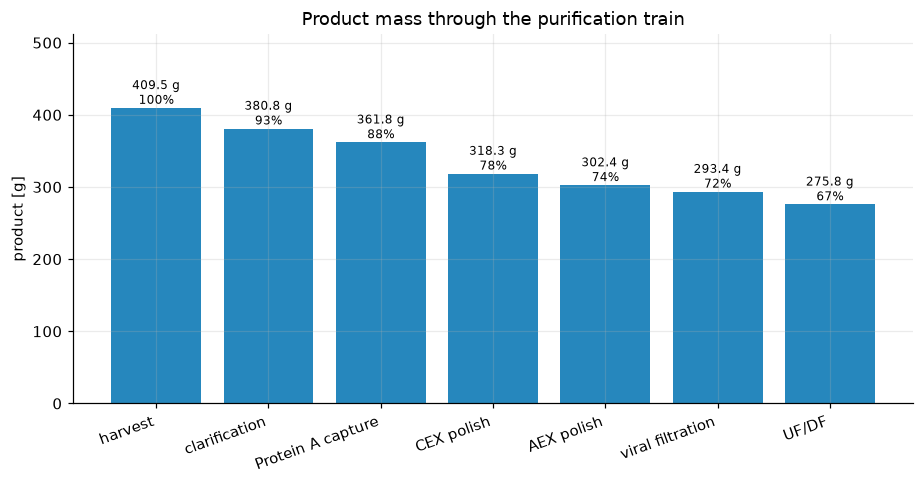

In [24]:
order = ask.ask("polishing_order", "Polishing steps, in order", str,
                choices=["polish_cex", "polish_aex"], multiple=True)

impurities = dict(config["downstream"]["feed_impurities"])
impurities["leached_protein_a_ng_per_mg"] = capture["leached_protein_a_ng_per_mg"]

steps = [{"step": "harvest", "yield_fraction": 1.0, "product_g": harvest_g, **impurities}]

clarified = {k: v for k, v in impurities.items()}
steps.append({"step": "clarification", "yield_fraction": float(config["downstream"]["clarification_yield"]),
              "product_g": clarified_g, **clarified})

# Capture: apply its clearance the same way a polishing step does.
product_g, impurities = downstream.polishing_step(
    "capture", clarified_g, impurities,
    yield_fraction=capture["yield_fraction"],
    hcp_log_reduction=capture["hcp_log_reduction"],
    dna_log_reduction=capture["dna_log_reduction"],
    aggregate_removal_fraction=capture["aggregate_removal_fraction"],
    protein_a_log_reduction=0.0,
)
impurities["leached_protein_a_ng_per_mg"] = capture["leached_protein_a_ng_per_mg"]
steps.append({"step": "Protein A capture", "yield_fraction": capture["yield_fraction"],
              "product_g": product_g, **impurities})

for name in order:
    section = config["downstream"][name]
    product_g, impurities = downstream.polishing_step(
        name, product_g, impurities,
        yield_fraction=float(section["yield_fraction"]),
        hcp_log_reduction=float(section["hcp_log_reduction"]),
        dna_log_reduction=float(section["dna_log_reduction"]),
        aggregate_removal_fraction=float(section["aggregate_removal_fraction"]),
        protein_a_log_reduction=float(section["protein_a_log_reduction"]),
    )
    steps.append({"step": name.replace("polish_", "").upper() + " polish",
                  "yield_fraction": float(section["yield_fraction"]), "product_g": product_g, **impurities})

viral_yield = float(config["downstream"]["viral_filtration"]["yield_fraction"])
product_g *= viral_yield
steps.append({"step": "viral filtration", "yield_fraction": viral_yield, "product_g": product_g, **impurities})

ufdf = config["downstream"]["ufdf"]
final = downstream.ufdf_step(
    product_g, max(product_g / 10.0, 1.0),
    target_concentration_g_per_L=float(ufdf["target_concentration_g_per_L"]),
    diavolumes=float(ufdf["diavolumes"]), yield_fraction=float(ufdf["yield_fraction"]),
    membrane_flux_LMH=float(ufdf["membrane_flux_LMH"]), area_m2=float(ufdf["area_m2"]),
)
steps.append({"step": "UF/DF", "yield_fraction": float(ufdf["yield_fraction"]),
              "product_g": final["product_out_g"], **impurities})

train = downstream.train_summary(steps)
display(train[["step", "yield_fraction", "cumulative_yield_fraction", "product_g",
               "hcp_ng_per_mg", "dna_pg_per_mg", "aggregate_percent", "leached_protein_a_ng_per_mg"]])

figure = plotting.yield_waterfall(train)
display(figure); plt.close(figure)
CHECKS.append(verification.verify_product_balance(train))

In [25]:
overall_yield = float(train["cumulative_yield_fraction"].iloc[-1])
print(f"INFO overall downstream yield {overall_yield:.1%}: "
      f"{harvest_g:,.1f} g harvested -> {final['product_out_g']:,.1f} g drug substance")
print(f"INFO final pool {final['final_volume_L']:.2f} L at {ufdf['target_concentration_g_per_L']:.0f} g/L, "
      f"{final['buffer_exchange_fraction']:.3%} buffer exchanged in {ufdf['diavolumes']:.0f} diavolumes")
print(f"INFO UF/DF process time {final['process_time_h']:.1f} h on {ufdf['area_m2']:.1f} m2")

# Log clearance achieved per impurity, end to end.
clearance = pd.DataFrame({
    "impurity": ["hcp_ng_per_mg", "dna_pg_per_mg", "aggregate_percent"],
    "feed": [train[c].iloc[0] for c in ["hcp_ng_per_mg", "dna_pg_per_mg", "aggregate_percent"]],
    "final": [train[c].iloc[-1] for c in ["hcp_ng_per_mg", "dna_pg_per_mg", "aggregate_percent"]],
})
clearance["log_reduction"] = np.log10(clearance["feed"] / clearance["final"])
display(clearance)

INFO overall downstream yield 67.3%: 409.5 g harvested -> 275.8 g drug substance
INFO final pool 3.45 L at 80 g/L, 99.966% buffer exchanged in 8 diavolumes
INFO UF/DF process time 3.1 h on 0.5 m2


,impurity,feed,final,log_reduction
0,hcp_ng_per_mg,2.2e+05,0.1103,6.3
1,dna_pg_per_mg,1.4e+06,0.01763,7.9
2,aggregate_percent,8,1.128,0.8507


In [26]:
run_cost = ask.ask("run_cost_estimate", "Estimate the direct materials bill?", bool)
if run_cost:
    annual_kg = ask.ask("annual_production_kg", "Annual production target", float, unit="kg",
                        minimum=0.1, maximum=5000)
    cost = simulators.biosteam_cost_estimate(
        annual_kg, titer_g_per_L=metrics["titer_mg_per_L"] / 1000.0, downstream_yield=overall_yield,
    )
    display(pd.Series(cost).to_frame("value"))
    print(f"\nINFO direct materials about ${cost['direct_materials_per_gram']:,.0f} per gram "
          f"at {annual_kg:g} kg/year ({cost['engine']})")
    print(f"WARN {cost['caveat']}")
    print(f"     That is {cost['materials_share_of_published_cogs']} of published cost of goods, "
          "which is the point: materials are not the bill.")
    if "note" in cost:
        print(f"INFO {cost['note']}")

    # What the titer is worth, in materials terms. This comparison is the one
    # the estimate can actually support.
    rows = []
    for factor in [0.5, 1.0, 2.0]:
        scenario = simulators.biosteam_cost_estimate(
            annual_kg, titer_g_per_L=factor * metrics["titer_mg_per_L"] / 1000.0,
            downstream_yield=overall_yield,
        )
        rows.append({"titer_g_per_L": factor * metrics["titer_mg_per_L"] / 1000.0,
                     "broth_L_per_year": scenario["broth_volume_L_per_year"],
                     "materials_per_gram": scenario["direct_materials_per_gram"]})
    display(pd.DataFrame(rows))

  run_cost_estimate = True   (default (no keyboard))
  annual_production_kg = 15.0 kg   (default (no keyboard))


,value
engine,bioproc arithmetic estimate (direct materials ...
broth_volume_L_per_year,"6,546"
media_cost_per_year,3.927e+04
buffer_cost_per_year,7.855e+04
resin_cost_per_year,4.5e+04
direct_materials_per_year,1.628e+05
direct_materials_per_gram,10.85
published_cogs_per_gram_low,50
published_cogs_per_gram_high,300
materials_share_of_published_cogs,3.6% to 21.7%



INFO direct materials about $11 per gram at 15 kg/year (bioproc arithmetic estimate (direct materials only))
WARN Direct materials only. Facility, labour, QC and fill-finish are excluded and dominate real cost of goods, published at $50-300/g for a commercial mAb. Use this to compare options, never as a cost of goods.
     That is 3.6% to 21.7% of published cost of goods, which is the point: materials are not the bill.


,titer_g_per_L,broth_L_per_year,materials_per_gram
0,1.701,1.309e+04,18.71
1,3.403,"6,546",10.85
2,6.805,"3,273",6.927


## 13. Release, control and capability

Three different questions, often confused:

- **Release** - does *this* batch meet its criteria? A miss is a process
  finding, reported as `OUT OF SPEC`, never a code failure.
- **Control** - is the process *stable*? An I-MR chart whose limits come from
  the moving range, so a shift shows up rather than being absorbed into wider
  limits.
- **Capability** - can the process *hold* the specification at its current
  spread and centring? `Cpk < 1.0` means it produces out-of-spec batches even
  while "in control".

In [27]:
criteria = quality.criteria_from_config(cfg.acceptance_criteria(config))
results = {
    "titer_mg_per_L": metrics["titer_mg_per_L"],
    "final_viability_percent": metrics["final_viability_percent"],
    "overall_yield_percent": 100 * overall_yield,
    "hcp_ng_per_mg": float(train["hcp_ng_per_mg"].iloc[-1]),
    "dna_pg_per_mg": float(train["dna_pg_per_mg"].iloc[-1]),
    "aggregate_percent": float(train["aggregate_percent"].iloc[-1]),
    "leached_protein_a_ng_per_mg": float(train["leached_protein_a_ng_per_mg"].iloc[-1]),
}
release = quality.release_table(results, criteria)
display(release)

out_of_spec = release[release["status"] == "OUT OF SPEC"]
not_measured = release[release["status"] == "NOT MEASURED"]
if out_of_spec.empty:
    print("INFO the batch meets every criterion that was measured")
else:
    for _, row in out_of_spec.iterrows():
        FINDINGS.append(f"{row['attribute']} = {row['value']:,.4g} {row['unit']} fails {row['criterion']}")
        print(f"OUT OF SPEC {FINDINGS[-1]}")
    print("\n     These are process findings, not code failures: the model ran correctly and")
    print("     the process missed the criterion.")
if not not_measured.empty:
    print(f"\nWARN not measured: {', '.join(not_measured['attribute'])} - an attribute nobody measured is not one that passed")

,attribute,kind,value,unit,criterion,margin,status
0,titer_mg_per_L,KPI,"3,403",mg/L,>= 3000 mg/L,402.7,PASS
1,final_viability_percent,PROCESS,69.4,%,>= 60 %,9.401,PASS
2,overall_yield_percent,KPI,67.35,%,>= 60 %,7.346,PASS
3,hcp_ng_per_mg,CQA,0.1103,ng/mg,<= 100 ng/mg,99.89,PASS
4,dna_pg_per_mg,CQA,0.01763,pg/mg,<= 10 pg/mg,9.982,PASS
5,aggregate_percent,CQA,1.128,%,<= 1.5 %,0.3718,PASS
6,leached_protein_a_ng_per_mg,CQA,0.03026,ng/mg,<= 10 ng/mg,9.97,PASS


INFO the batch meets every criterion that was measured


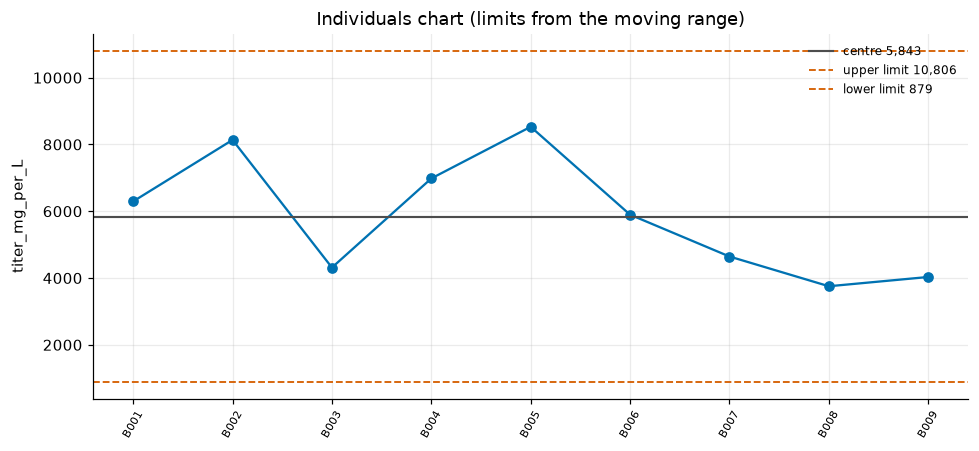

INFO 0 of 9 batches flagged; sigma estimated from the moving range = 1,654.5
INFO the process is in statistical control over this campaign
WARN this campaign varies clone, feed_strategy by design, so the spread across
     all batches is not process variation. Capability is reported per group below;
     the all-batches figure is shown only for contrast.


,group,n,mean,sd,cpk,out_of_spec_batches
0,"clone=A, feed_strategy=glucose_setpoint",5,"5,563","1,876",0.4553,0
1,"clone=B, feed_strategy=fixed_bolus",4,"6,193","1,865",0.5707,0
2,ALL BATCHES (not process capability),9,"5,843","1,782",0.5319,0



INFO best group (clone=B, feed_strategy=fixed_bolus): Cpk = 0.57, NOT capable against >= 3000 mg/L
WARN even the best group has Cpk 0.57 < 1.0 for titer_mg_per_L: out-of-spec batches are expected


In [28]:
# Control chart across the campaign's batches.
chart_target = "titer_mg_per_L" if "titer_mg_per_L" in batches.columns else target
if len(batches) >= 3 and chart_target in batches.columns:
    chart, limits = quality.control_chart(batches[chart_target], labels=batches["batch_id"])
    figure, axis = plt.subplots(figsize=(9, 4.2))
    axis.plot(range(len(chart)), chart["value"], marker="o", color=plotting.OKABE_ITO[0])
    axis.axhline(limits["centre"], color="0.3", linewidth=1.4, label=f"centre {limits['centre']:,.0f}")
    for key, style in [("upper", "--"), ("lower", "--")]:
        axis.axhline(limits[key], color=plotting.OKABE_ITO[1], linestyle=style, linewidth=1.2,
                     label=f"{key} limit {limits[key]:,.0f}")
    flagged = chart[chart["out_of_control"] | chart["run_rule"]]
    if not flagged.empty:
        axis.scatter(flagged.index, flagged["value"], s=130, facecolor="none",
                     edgecolor=plotting.OKABE_ITO[1], linewidth=2, zorder=4, label="flagged")
    axis.set_xticks(range(len(chart))); axis.set_xticklabels(chart["batch"], rotation=60, fontsize=7)
    axis.set_ylabel(chart_target); axis.set_title("Individuals chart (limits from the moving range)")
    axis.legend(frameon=False, fontsize=8)
    display(figure); plt.close(figure)

    print(f"INFO {len(flagged)} of {len(chart)} batches flagged; "
          f"sigma estimated from the moving range = {limits['sigma_estimate']:,.1f}")
    if flagged.empty:
        print("INFO the process is in statistical control over this campaign")
    else:
        FINDINGS.append(f"{len(flagged)} batch(es) outside the control limits or on a run")
        print(f"WARN {FINDINGS[-1]}")

    # Capability only means something across batches run the same way. The
    # campaign deliberately mixes clones and feed strategies, so its spread is
    # mostly design variation; computing Cpk over all of it understates the
    # process. Report it per homogeneous group where the campaign has them.
    design_columns = [c for c in ["clone", "feed_strategy"] if c in batches.columns
                      and batches[c].nunique() > 1]
    matching = [c for c in criteria if c.name == chart_target]
    if matching:
        criterion = matching[0]
        if design_columns:
            print(f"WARN this campaign varies {', '.join(design_columns)} by design, so the spread across")
            print("     all batches is not process variation. Capability is reported per group below;")
            print("     the all-batches figure is shown only for contrast.")
            rows = []
            for keys, group in batches.groupby(design_columns):
                if len(group) < 3:
                    continue
                label = ", ".join(f"{c}={v}" for c, v in zip(design_columns, np.atleast_1d(keys), strict=True))
                rows.append({"group": label, **quality.capability(group[chart_target], criterion)})
            rows.append({"group": "ALL BATCHES (not process capability)",
                         **quality.capability(batches[chart_target], criterion)})
            display(pd.DataFrame(rows)[["group", "n", "mean", "sd", "cpk", "out_of_spec_batches"]])
            best = max((r for r in rows if "ALL" not in r["group"]), key=lambda r: r["cpk"], default=None)
            if best:
                verdict = ("capable" if best["cpk"] >= 1.33 else
                           "marginal" if best["cpk"] >= 1.0 else "NOT capable")
                print(f"\nINFO best group ({best['group']}): Cpk = {best['cpk']:.2f}, {verdict} "
                      f"against {criterion.describe()}")
                if best["cpk"] < 1.0:
                    FINDINGS.append(
                        f"even the best group has Cpk {best['cpk']:.2f} < 1.0 for {chart_target}: "
                        "out-of-spec batches are expected"
                    )
                    print(f"WARN {FINDINGS[-1]}")
        else:
            capability = quality.capability(batches[chart_target], criterion)
            display(pd.Series(capability).to_frame("value"))
            verdict = ("capable" if capability["cpk"] >= 1.33 else
                       "marginal" if capability["cpk"] >= 1.0 else "NOT capable")
            print(f"INFO Cpk = {capability['cpk']:.2f}: the process is {verdict} against {criterion.describe()}")
            if capability["cpk"] < 1.0:
                FINDINGS.append(f"Cpk {capability['cpk']:.2f} < 1.0 for {chart_target}: out-of-spec batches are expected")
                print(f"WARN {FINDINGS[-1]}")
else:
    print("INFO fewer than 3 batches: no control chart")

### Validation is not done here

Everything above is **verification** plus screening on synthetic or historical
data. Validation - are these the right equations for *your* process? - needs
independent experimental data that was not used to build or calibrate the model:
measured breakthrough curves from your resin, offline assays alongside the
spectra, release data from batches the models never saw.

The honest summary of this notebook's status is in the record below.

## 14. The record: what was run, how, and on what

Every reported number needs its context: software versions, seed, answers,
provenance of the data and the time it took (ground rules section 4). The last
cell raises if any verification check failed.

In [29]:
display(Markdown("### Your answers"))
display(ask.table())
answers_path = ask.save(DATA / "answers.json")
print(f"INFO saved to {ui.short_path(answers_path)}")
print(f"     replay this exact run with:  BIOPROC_ANSWERS={ui.short_path(answers_path)} python tools/make_notebook.py --execute")
if ask.notes:
    for note in ask.notes:
        print(f"INFO {note}")

### Your answers

,key,value,unit,source,prompt
0,run_convergence_study,True,,default (no keyboard),Run the time-step convergence study? (a few se...
1,data_source,simulate,,default (no keyboard),Where should the batch data come from?
2,n_batches,9,,default (no keyboard),How many batches in the campaign?
3,lot_variation_cv,0.1,,default (no keyboard),Lot-to-lot variation in growth and productivit...
4,scale_L,50,L,default (no keyboard),Working volume at inoculation
5,feed_strategy,fixed_bolus,,default (no keyboard),Feed strategy
6,duration_d,21,d,default (no keyboard),Culture duration
7,shift_day,5,d,default (no keyboard),Temperature-shift day (99 = no shift)
8,strategy_replicates,5,,default (no keyboard),Replicate batches per feed strategy
9,run_sensitivity,True,,default (no keyboard),Run the Sobol sensitivity study?


INFO saved to ~/bioproc-data/demo_intensified/answers.json
     replay this exact run with:  BIOPROC_ANSWERS=~/bioproc-data/demo_intensified/answers.json python tools/make_notebook.py --execute
INFO No keyboard available; config defaults used from here on.


In [30]:
display(Markdown("### Provenance and environment"))
import importlib.metadata as metadata

versions = {}
for package in ["numpy", "scipy", "pandas", "scikit-learn", "matplotlib", "SALib"]:
    try:
        versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        versions[package] = "not installed"

record = {
    "system": SYSTEM,
    "config": ui.short_path(config["_path"]),
    "seed": SEED,
    "data_provenance": PROVENANCE,
    "units_confirmed": UNITS_KNOWN,
    "python": platform.python_version(),
    "platform": f"{platform.system()} {platform.release()} ({platform.machine()})",
    "packages": versions,
    "optional_engines": {row["key"]: (row["version"] or "yes") if row["available"] else "not installed"
                         for _, row in engines.iterrows()},
    "runtime_s": round(time.perf_counter() - NOTEBOOK_START, 1),
}
print(json.dumps(record, indent=2, default=str))
(DATA / "run_record.json").write_text(json.dumps(record, indent=2, default=str), encoding="utf-8", newline="")

### Provenance and environment

{
  "system": "demo_intensified",
  "config": "configs/systems/demo_intensified.toml",
  "seed": 20261116,
  "data_provenance": {
    "source": "simulated",
    "generator": "bioproc.data.simulate_campaign",
    "seed": 20261116
  },
  "units_confirmed": true,
  "python": "3.11.18",
  "platform": "Windows 10 (AMD64)",
  "packages": {
    "numpy": "2.3.5",
    "scipy": "1.17.1",
    "pandas": "3.1.1",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2",
    "SALib": "1.6.0"
  },
  "optional_engines": {
    "cadet": "not installed",
    "biosteam": "not installed",
    "idaes": "not installed",
    "dwsim": "not installed"
  },
  "runtime_s": 88.3
}


659

In [31]:
display(Markdown("### Verification summary"))
display(verification.summarise(CHECKS))

display(Markdown("### Process findings (not code failures)"))
if FINDINGS:
    for finding in FINDINGS:
        print(f"  - {finding}")
else:
    print("  none")

if PROVENANCE.get("source") == "simulated":
    print("\nWARN Every number above comes from SYNTHETIC data. It demonstrates that the")
    print("     analysis recovers a known answer. It is not evidence about any real process.")
if not UNITS_KNOWN:
    print("\nWARN The data's units were not confirmed, so absolute values are not interpretable.")

# Fails the notebook if any check failed; this is what CI enforces.
verification.raise_on_failure(CHECKS)
print(f"\nAll {len(CHECKS)} verification checks passed. "
      f"Notebook runtime {time.perf_counter() - NOTEBOOK_START:.1f} s.")

### Verification summary

,check,status,observed,expected,relative_error,tolerance,note
0,Batch growth matches x0*exp(mu*t) with nutrien...,PASS,2.11,2.11,4.489e-09,0.002,Analytic solution of the model's own limiting ...
1,Langmuir isotherm closed form,PASS,50.77,50.77,0,1e-10,
2,Diafiltration buffer exchange = 1 - exp(-N),PASS,0.9991,0.9991,0,1e-09,"Fully permeable solute, perfectly mixed retentate"
3,Titer is converged at max_step = 1 h,PASS,4.608e-08,0,4.608e-08,0.001,relative to the 0.25 h solution
4,Glucose mass balance over the culture,PASS,0,0,0,1e-06,"fed 95879.822 mmol, consumed 4660.620 mmol (in..."
5,Product mass balance across the purification t...,PASS,1.388e-16,0,1.388e-16,1e-09,Each step: out = in * yield


### Process findings (not code failures)

  - the hybrid correction does not improve on the mechanistic model alone
  - 11 capture cycles per batch is operationally heavy
  - even the best group has Cpk 0.57 < 1.0 for titer_mg_per_L: out-of-spec batches are expected

WARN Every number above comes from SYNTHETIC data. It demonstrates that the
     analysis recovers a known answer. It is not evidence about any real process.

All 6 verification checks passed. Notebook runtime 88.4 s.
